# SecureFinance Africa – AI Ethics, Governance & Compliance Assessment

In [1]:
# ==== 1. SETUP ====
!pip install -q python-docx openpyxl
import os, warnings, zipfile, datetime, re
import numpy as np, pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.inspection import permutation_importance
from sklearn.metrics import roc_auc_score, accuracy_score, precision_score, recall_score, f1_score
warnings.filterwarnings("ignore")

SEED = 42
np.random.seed(SEED)
BASE = "securefinance-ai-assessment"
for d in ["report", "risk-register", "data", "analysis", "outputs", "docs"]:
    os.makedirs(f"{BASE}/{d}", exist_ok=True)
pd.set_option("display.width", 200, "display.max_columns", 30)
print("Folders ready:", sorted(os.listdir(BASE)))

Folders ready: ['analysis', 'data', 'docs', 'outputs', 'report', 'risk-register']


## 2. Synthetic dataset (Task 4 – dataset design)
 True fraud depends on *behaviour* (night activity, new accounts, transaction size, verification score) and **not** on region. But rural customers are simulated to use basic phones more, transact at night slightly more, and have lower facial/ID verification scores (e.g. lower camera quality, patchy connectivity). The model never sees `region`, yet these features may act as **proxies** and cause unequal false-positive rates. Because verification score lowers fraud risk in the simulation, rural customers also end up with a higher *base rate* of simulated fraud; so some selection-rate gap is expected, which is why **FPR parity** (harm to genuine customers) is the primary metric. This is a *fictional illustration*, not a claim about real Nigerian populations.

In [2]:
# ==== 2. GENERATE SYNTHETIC DATA ====
rng = np.random.default_rng(SEED)
n = 8000
region = rng.choice(["Urban", "Rural"], n, p=[0.65, 0.35])
rural = region == "Rural"
gender = rng.choice(["F", "M"], n)
age = rng.integers(18, 70, n)
income_band = rng.choice(["Low", "Mid", "High"], n, p=[0.4, 0.4, 0.2])
account_age = rng.integers(1, 120, n)
avg_txn = rng.lognormal(10, 0.8, n).round(2)
txn_count = rng.poisson(25, n)
night_ratio = np.clip(rng.beta(2, 8, n) + np.where(rural, 0.07, 0), 0, 1)
device = np.where(rng.random(n) < np.where(rural, 0.60, 0.20), "Basic", "Smartphone")
verif = np.clip(rng.normal(0.85, 0.08, n) - np.where(rural, 0.07, 0), 0, 1)

# Ground truth fraud: NO direct dependence on region/gender
logit = (-5.4 + 7.0*night_ratio + 2.0*(account_age < 6)
         + 0.6*(np.log(avg_txn) - 10) - 9.0*(verif - 0.85))
is_fraud = (rng.random(n) < 1/(1 + np.exp(-logit))).astype(int)

df = pd.DataFrame({
    "customer_id": [f"SYN{i:05d}" for i in range(n)],   # fake IDs only
    "age": age, "gender": gender, "region": region, "income_band": income_band,
    "account_age_months": account_age, "avg_monthly_txn": avg_txn, "txn_count": txn_count,
    "night_txn_ratio": night_ratio.round(3), "device_type": device,
    "verification_score": verif.round(3), "is_fraud": is_fraud})
df.to_csv(f"{BASE}/data/synthetic_data.csv", index=False)

dictionary = pd.DataFrame([
 ("customer_id","Fake sequential ID (no real identifiers, no BVN/NIN/phone)"),
 ("age","Integer 18-69"),("gender","F/M (simulated, used ONLY for fairness testing)"),
 ("region","Urban/Rural (used ONLY for fairness testing, NOT a model input)"),
 ("income_band","Low/Mid/High"),("account_age_months","Account tenure in months"),
 ("avg_monthly_txn","Average monthly transaction value (fictional currency units)"),
 ("txn_count","Transactions per month"),("night_txn_ratio","Share of transactions at night (0-1)"),
 ("device_type","Basic phone vs Smartphone"),("verification_score","Simulated ID/face verification confidence (0-1)"),
 ("is_fraud","Simulated ground truth label (1 = fraud)")], columns=["column","description"])
dictionary.to_csv(f"{BASE}/data/data_dictionary.csv", index=False)

print(df.shape, "| overall fraud rate:", round(df.is_fraud.mean(), 4))
print(df.groupby("region")[["is_fraud","night_txn_ratio","verification_score"]].mean().round(3))
print(df.groupby("region")["device_type"].apply(lambda s: (s=="Basic").mean()).round(3).rename("share_basic_phone"))
df.head()

(8000, 12) | overall fraud rate: 0.0624
        is_fraud  night_txn_ratio  verification_score
region                                               
Rural      0.111            0.271               0.780
Urban      0.037            0.200               0.847
region
Rural    0.600
Urban    0.201
Name: share_basic_phone, dtype: float64


,customer_id,age,gender,region,income_band,account_age_months,avg_monthly_txn,txn_count,night_txn_ratio,device_type,verification_score,is_fraud
0,SYN00000,65,M,Rural,Mid,23,51089.64,23,0.243,Basic,0.873,0
1,SYN00001,44,M,Urban,Low,92,21837.43,29,0.258,Smartphone,0.891,0
2,SYN00002,49,F,Rural,Low,40,34337.89,29,0.269,Smartphone,0.726,0
3,SYN00003,36,M,Rural,Low,65,25291.01,21,0.220,Basic,0.737,0
4,SYN00004,64,M,Urban,Low,109,67711.22,33,0.301,Basic,0.847,0


## 3. Task 1 – Ethical risk identification

In [3]:
# ==== 3. TASK 1: ETHICAL RISKS ====
ethical_risks = pd.DataFrame([
 {"ID":"E1","Risk":"Algorithmic bias in fraud flags","Theme":"Bias",
  "Cause":"Training data under-represents rural/thin-file customers; features such as device type and verification score act as proxies for region/income.",
  "Stakeholders":"Rural and low-income customers; SecureFinance; regulators",
  "Consequences":"Disproportionate account freezes, delayed payments, discrimination claims, reputational harm.",
  "Proportionate control":"Pre-deployment and quarterly bias testing (FPR parity), representative data, proxy review, mandatory human review of adverse flags.",
  "Principle link":"NIST 'Fair - harmful bias managed'; UNESCO fairness and non-discrimination; OECD human-centred values and fairness"},
 {"ID":"E2","Risk":"Excessive/unlawful personal-data processing","Theme":"Privacy",
  "Cause":"Collection of biometrics, ID numbers and transaction histories beyond need; repurposing of data; weak retention limits.",
  "Stakeholders":"Data subjects; NDPC; SecureFinance",
  "Consequences":"Unlawful processing, regulatory sanction, loss of trust, surveillance concerns.",
  "Proportionate control":"DPIA before launch, data minimisation, defined lawful basis, encryption, retention schedule, access controls.",
  "Principle link":"NIST 'Privacy-enhanced'; UNESCO right to privacy and data protection; OECD robustness, security and safety"},
 {"ID":"E3","Risk":"Unfair financial exclusion (false positives)","Theme":"Fairness",
  "Cause":"Conservative thresholds tuned for fraud capture; no cost weighting of wrongly flagging genuine customers.",
  "Stakeholders":"Genuine customers, especially informal-sector earners",
  "Consequences":"Blocked access to funds, income loss, financial exclusion.",
  "Proportionate control":"FPR targets per group, threshold review, fast appeal route with human decision, temporary-hold instead of freeze.",
  "Principle link":"UNESCO proportionality and do no harm; OECD inclusive growth"},
 {"ID":"E4","Risk":"Opaque, unexplainable decisions","Theme":"Transparency",
  "Cause":"Complex models without reason codes or documentation.",
  "Stakeholders":"Customers, reviewers, auditors, regulators",
  "Consequences":"Customers cannot understand or contest outcomes; auditors cannot verify; weakened accountability.",
  "Proportionate control":"Reason codes per decision, model card, explanation tooling (permutation importance, counterfactual checks), plain-language notices.",
  "Principle link":"NIST 'Explainable and interpretable'; UNESCO transparency and explainability; OECD transparency"},
 {"ID":"E5","Risk":"Weak or symbolic human oversight (automation bias)","Theme":"Human oversight",
  "Cause":"Reviewers under time pressure rubber-stamp scores; no authority or training to override.",
  "Stakeholders":"Reviewers, customers",
  "Consequences":"Errors uncorrected; accountability gap; potential breach of rights on automated decisions.",
  "Proportionate control":"Mandatory meaningful review for adverse outcomes, override logging and override-rate monitoring, reviewer training, SLA that allows time to review.",
  "Principle link":"UNESCO human oversight and determination; OECD accountability"},
 {"ID":"E6","Risk":"Biometric verification performance gaps","Theme":"Bias / Privacy",
  "Cause":"Face-matching trained on unrepresentative images; poor camera quality on low-end devices.",
  "Stakeholders":"Customers with darker skin tones, older customers, low-end device users",
  "Consequences":"Onboarding failure, repeated rejection, exclusion.",
  "Proportionate control":"Group-level verification error testing, alternative non-biometric verification path, liveness tuning for low-end cameras.",
  "Principle link":"NIST 'Valid and reliable'; UNESCO fairness"},
 {"ID":"E7","Risk":"Model drift and security manipulation","Theme":"Robustness",
  "Cause":"Fraud patterns change; adversaries probe the model; data pipeline changes.",
  "Stakeholders":"Customers, SecureFinance",
  "Consequences":"Falling accuracy, rising false positives or missed fraud, financial loss.",
  "Proportionate control":"Drift monitoring, retraining policy, red-teaming, rollback criteria, secure MLOps.",
  "Principle link":"NIST 'Secure and resilient'; OECD robustness, security and safety"}])
ethical_risks.to_csv(f"{BASE}/risk-register/ethical_risks_task1.csv", index=False)
print("Most severe (analyst judgement): E1/E3 – the false-positive harm falls on people least able to absorb it.")
ethical_risks[["ID","Risk","Theme","Stakeholders"]]

Most severe (analyst judgement): E1/E3 – the false-positive harm falls on people least able to absorb it.


,ID,Risk,Theme,Stakeholders
0,E1,Algorithmic bias in fraud flags,Bias,Rural and low-income customers; SecureFinance;...
1,E2,Excessive/unlawful personal-data processing,Privacy,Data subjects; NDPC; SecureFinance
2,E3,Unfair financial exclusion (false positives),Fairness,"Genuine customers, especially informal-sector ..."
3,E4,"Opaque, unexplainable decisions",Transparency,"Customers, reviewers, auditors, regulators"
4,E5,Weak or symbolic human oversight (automation b...,Human oversight,"Reviewers, customers"
5,E6,Biometric verification performance gaps,Bias / Privacy,"Customers with darker skin tones, older custom..."
6,E7,Model drift and security manipulation,Robustness,"Customers, SecureFinance"


## 4. Task 2 – Governance (NIST AI RMF) and AI risk register

In [6]:
# ==== 4A. NIST AI RMF GOVERNANCE MAPPING ====
nist = pd.DataFrame([
 ("GOVERN","Governance responsibilities","Board-approved AI policy; AI Ethics & Risk Committee (CRO chair, DPO, Head of Data Science, Compliance, Internal Audit, customer-advocate); three-lines-of-defence; named model owner; vendor policy; staff training."),
 ("MAP","Risk identification","System card (purpose, users, data, affected groups, legal context, foreseeable misuse); DPIA; stakeholder consultation; ethical risk analysis (Section 3)."),
 ("MEASURE","Risk measurement","Metrics: accuracy, precision, recall, FPR/TPR by group, disparate-impact ratio, drift (PSI), explanation coverage, reviewer override rate; pen-testing; thresholds and test frequency set in policy."),
 ("MANAGE","Mitigation","Treat risks (avoid/mitigate/transfer/accept) via the register; proxy-feature controls; threshold review; alternative verification path; appeal process."),
 ("MANAGE","Monitoring","Monthly dashboard (FPR gap, selection-rate ratio, drift, complaints); quarterly fairness audit; annual independent review; rollback triggers."),
 ("GOVERN/MANAGE","Human oversight","Meaningful human review of all adverse decisions; override logging; reviewer training; authority to suspend the model."),
 ("MANAGE","Incident escalation","Four-level severity ladder with time limits (below); kill-switch authority; regulator notification where personal data is breached."),
], columns=["NIST function","Required element","SecureFinance approach"])
nist.to_csv(f"{BASE}/risk-register/nist_mapping.csv", index=False)

escalation = pd.DataFrame([
 ("Level 1 - Minor","Isolated error, no customer harm","Model owner","Log within 1 working day; fix in normal cycle"),
 ("Level 2 - Moderate","Metric breach (e.g. FPR ratio > 1.25) or spike in complaints","Head of Data Science -> CRO","Escalate within 24h; mitigation plan in 5 days; increase human review"),
 ("Level 3 - Major","Confirmed discriminatory outcome or large wrongful freezes","CRO + DPO + Compliance; Committee convened","Escalate within 4h; switch to manual review or fallback rules; remediate affected customers"),
 ("Level 4 - Critical","Personal-data breach, systemic harm, or regulatory action","CEO + Board + DPO","Immediate suspension of model; notify the NDPC within 72 hours of awareness where individuals' rights are at risk (NDPA s.40(2)); inform affected individuals immediately where risk is high"),
], columns=["Severity","Trigger","Escalate to","Response time and action"])
escalation.to_csv(f"{BASE}/risk-register/escalation_ladder.csv", index=False)
display(nist); display(escalation)

,NIST function,Required element,SecureFinance approach
0,GOVERN,Governance responsibilities,Board-approved AI policy; AI Ethics & Risk Com...
1,MAP,Risk identification,"System card (purpose, users, data, affected gr..."
2,MEASURE,Risk measurement,"Metrics: accuracy, precision, recall, FPR/TPR ..."
3,MANAGE,Mitigation,Treat risks (avoid/mitigate/transfer/accept) v...
4,MANAGE,Monitoring,"Monthly dashboard (FPR gap, selection-rate rat..."
5,GOVERN/MANAGE,Human oversight,Meaningful human review of all adverse decisio...
6,MANAGE,Incident escalation,Four-level severity ladder with time limits (b...


,Severity,Trigger,Escalate to,Response time and action
0,Level 1 - Minor,"Isolated error, no customer harm",Model owner,Log within 1 working day; fix in normal cycle
1,Level 2 - Moderate,Metric breach (e.g. FPR ratio > 1.25) or spike...,Head of Data Science -> CRO,Escalate within 24h; mitigation plan in 5 days...
2,Level 3 - Major,Confirmed discriminatory outcome or large wron...,CRO + DPO + Compliance; Committee convened,Escalate within 4h; switch to manual review or...
3,Level 4 - Critical,"Personal-data breach, systemic harm, or regula...",CEO + Board + DPO,Immediate suspension of model; notify the NDPC...


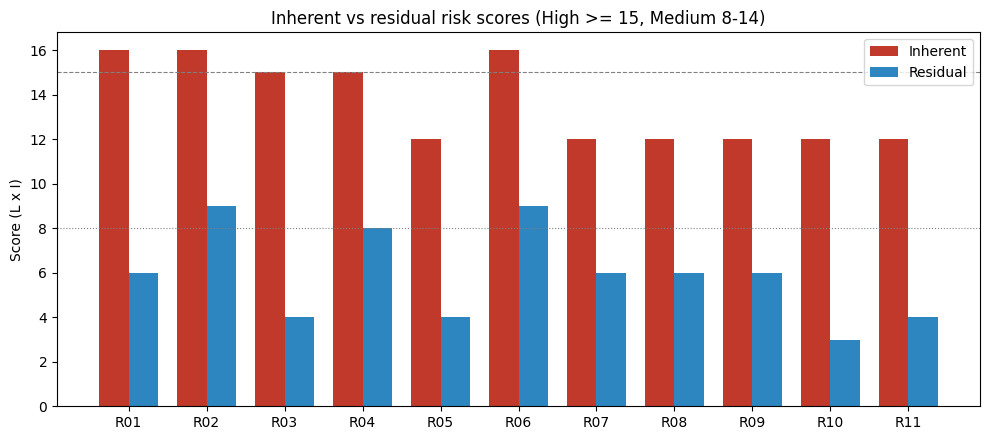

{'Medium': 6, 'High': 5} -> {'Low': 8, 'Medium': 3}


,ID,Risk description,Inherent score,Residual score,Accountable owner (role)
0,R01,Biased fraud flags disadvantage rural/low-inco...,16,6,Head of Data Science
1,R02,Biometric/ID verification error gaps across sk...,16,9,Head of Identity Products
2,R03,"No valid lawful basis, or invalid consent, for...",15,4,Data Protection Officer
3,R04,Personal data breach / unauthorised access,15,8,Chief Information Security Officer
4,R05,Lack of explainability prevents customers and ...,12,4,Model Owner
5,R06,Automation bias: reviewers rubber-stamp model ...,16,9,Head of Fraud Operations
6,R07,Model drift degrades accuracy and fairness ove...,12,6,Model Owner
7,R08,"Vendor/third-party dependency (cloud, KYC/biom...",12,6,Chief Risk Officer
8,R09,Adversarial evasion and model manipulation by ...,12,6,Chief Information Security Officer
9,R10,Cross-border data transfer non-compliance (clo...,12,3,Data Protection Officer


In [7]:
# ==== 4B. AI RISK REGISTER (10 risks) ====
rows = [
 ("R01","Biased fraud flags disadvantage rural/low-income customers","Head of Data Science",4,4,"Quarterly group FPR parity audit (threshold ratio <=1.25), proxy review, human review of adverse flags",2,3,"Controls reduce likelihood; impact stays moderate because some harm to individuals remains possible"),
 ("R02","Biometric/ID verification error gaps across skin tone, age and device quality","Head of Identity Products",4,4,"Group-level error testing; non-biometric fallback; liveness tuning",3,3,"Fallback path limits exclusion but technical gap cannot be fully removed"),
 ("R03","No valid lawful basis, or invalid consent, for processing (incl. sensitive biometric data)","Data Protection Officer",3,5,"DPIA; lawful-basis register; consent UX review; legal sign-off",1,4,"Documented basis, DPIA and sign-off reduce the probability of unlawful processing; controls lower likelihood but cannot remove the consequence, so impact stays high"),
 ("R04","Personal data breach / unauthorised access","Chief Information Security Officer",3,5,"Encryption at rest/in transit, access control, logging, pen-tests, incident response",2,4,"Strong controls lower probability; consequence of a breach is still serious"),
 ("R05","Lack of explainability prevents customers and auditors contesting decisions","Model Owner",4,3,"Reason codes, model card, permutation importance, counterfactual review",2,2,"Explanations make decisions contestable; impact reduced"),
 ("R06","Automation bias: reviewers rubber-stamp model outputs","Head of Fraud Operations",4,4,"Meaningful review rules, override-rate monitoring, training, time allowance",3,3,"Cultural risk persists; monitoring detects it early"),
 ("R07","Model drift degrades accuracy and fairness over time","Model Owner",4,3,"Drift monitoring (PSI), scheduled retraining, rollback criteria",2,3,"Monitoring shortens detection time"),
 ("R08","Vendor/third-party dependency (cloud, KYC/biometric APIs) without adequate assurance","Chief Risk Officer",3,4,"Vendor due diligence, contractual audit/data clauses, exit plan",2,3,"Contracts and exit plan reduce exposure"),
 ("R09","Adversarial evasion and model manipulation by fraudsters","Chief Information Security Officer",3,4,"Red-teaming, rate-limiting, ensemble with rules, anomaly alerts",2,3,"Cannot be eliminated; arms race continues"),
 ("R10","Cross-border data transfer non-compliance (cloud hosting or later expansion)","Data Protection Officer",3,4,"Transfer impact assessment; contractual safeguards; hosting-location policy; check NDPA transfer rules",1,3,"Policy gating prevents unapproved transfers"),
 ("R11","Inadequate complaints, appeal and redress route","Head of Customer Operations",3,4,"Published appeal process, human decision within 48h, redress tracking",2,2,"Clear SLA and tracking mitigate harm"),
]
rr = pd.DataFrame(rows, columns=["ID","Risk description","Accountable owner (role)","Likelihood (1-5)","Impact (1-5)",
                                 "Existing/proposed control","Residual likelihood","Residual impact","Residual rationale"])
rr["Inherent score"] = rr["Likelihood (1-5)"] * rr["Impact (1-5)"]
rr["Residual score"] = rr["Residual likelihood"] * rr["Residual impact"]
band = lambda s: "High" if s >= 15 else ("Medium" if s >= 8 else "Low")
rr["Inherent rating"] = rr["Inherent score"].map(band)
rr["Residual rating"] = rr["Residual score"].map(band)
rr["Status"] = "Proposed"
assert (rr["Residual score"] < rr["Inherent score"]).all(), "Residual must be lower than inherent"
rr = rr[["ID","Risk description","Likelihood (1-5)","Impact (1-5)","Inherent score","Inherent rating",
         "Accountable owner (role)","Existing/proposed control","Residual likelihood","Residual impact",
         "Residual score","Residual rating","Residual rationale","Status"]]

# save csv + coloured xlsx
rr.to_csv(f"{BASE}/risk-register/risk_register.csv", index=False)
with pd.ExcelWriter(f"{BASE}/risk-register/risk_register.xlsx", engine="openpyxl") as xw:
    rr.to_excel(xw, sheet_name="AI Risk Register", index=False)
    ethical_risks.to_excel(xw, sheet_name="Ethical risks", index=False)
    nist.to_excel(xw, sheet_name="NIST mapping", index=False)
    escalation.to_excel(xw, sheet_name="Escalation ladder", index=False)
from openpyxl import load_workbook
from openpyxl.styles import PatternFill, Font, Alignment
wb = load_workbook(f"{BASE}/risk-register/risk_register.xlsx")
for ws in wb.worksheets:
    for c in ws[1]:
        c.font = Font(bold=True, color="FFFFFF"); c.fill = PatternFill("solid", fgColor="1F3A5F")
    for col in ws.columns:
        ws.column_dimensions[col[0].column_letter].width = 28
    for row in ws.iter_rows(min_row=2):
        for c in row: c.alignment = Alignment(wrap_text=True, vertical="top")
ws = wb["AI Risk Register"]
colors = {"High":"F4B6B6","Medium":"FFE699","Low":"C6E0B4"}
for r in range(2, ws.max_row+1):
    for col in (6, 12):
        c = ws.cell(r, col); c.fill = PatternFill("solid", fgColor=colors[c.value])
wb.save(f"{BASE}/risk-register/risk_register.xlsx")

# chart: inherent vs residual
fig, ax = plt.subplots(figsize=(10, 4.5))
x = np.arange(len(rr)); w = 0.38
ax.bar(x-w/2, rr["Inherent score"], w, label="Inherent", color="#C0392B")
ax.bar(x+w/2, rr["Residual score"], w, label="Residual", color="#2E86C1")
ax.axhline(15, ls="--", c="grey", lw=0.8); ax.axhline(8, ls=":", c="grey", lw=0.8)
ax.set_xticks(x); ax.set_xticklabels(rr["ID"]); ax.set_ylabel("Score (L x I)")
ax.set_title("Inherent vs residual risk scores (High >= 15, Medium 8-14)"); ax.legend()
plt.tight_layout(); plt.savefig(f"{BASE}/outputs/risk_inherent_vs_residual.png", dpi=150); plt.show()
print(rr["Inherent rating"].value_counts().to_dict(), "->", rr["Residual rating"].value_counts().to_dict())
rr[["ID","Risk description","Inherent score","Residual score","Accountable owner (role)"]]

## 5. Task 3 – Legal and regulatory compliance

In [8]:
# ==== 5. LEGAL & REGULATORY TABLE ====
legal = pd.DataFrame([
 {"Instrument":"Nigeria Data Protection Act 2023 and NDPC General Application and Implementation Directive (GAID) 2025",
  "Status":"BINDING LAW",
  "Applies when":"Processing personal data of data subjects in Nigeria, or by controllers/processors established in or targeting Nigeria. Applies to the Nigerian deployment from day one.",
  "Key obligations for SecureFinance":"Lawful basis and principles; data-subject rights incl. rights on automated decision-making; extra care for sensitive data (biometrics); DPIA for high-risk processing; security; breach notification to NDPC; cross-border transfer conditions; DPO / registration if a data controller/processor of major importance.",
  "Section references":"NDPA ss.2, 24, 25, 28, 29, 30, 32, 37, 40, 41-43, 44; GAID Arts 1, 8-9, 18, 28, 33-34, 41-45"},
 {"Instrument":"EU AI Act - Regulation (EU) 2024/1689",
  "Status":"BINDING LAW (conditional, extra-territorial)",
  "Applies when":"Only if the system is placed on the EU market or its output is used in the EU. NOT applicable to a Nigeria-only deployment. Becomes relevant on EU expansion or if EU residents' data/outputs are involved.",
  "Key obligations for SecureFinance":"Credit-worthiness/credit scoring of natural persons is listed as high-risk (Annex III) while fraud-detection is carved out; identity-verification biometrics have specific treatment. If high-risk: risk management, data governance, documentation, logging, transparency, human oversight, accuracy/robustness, conformity assessment. Annex III high-risk obligations apply from 2 December 2027 under Regulation (EU) 2026/1744.",
  "Section references":"Art. 2(1) (scope); Annex III points 1(a) and 5(b); Regulation (EU) 2026/1744 (application dates)"},
 {"Instrument":"UNESCO Recommendation on the Ethics of AI (2021)",
  "Status":"NON-BINDING (soft law)",
  "Applies when":"Voluntary; adopted by UNESCO member states incl. Nigeria but creates no direct legal duties for a company.",
  "Key obligations for SecureFinance":"Benchmark: proportionality and do-no-harm, privacy, fairness and non-discrimination, transparency and explainability, human oversight, accountability, ethical impact assessment.",
  "Section references":"Values and principles sections of the 2021 Recommendation"},
 {"Instrument":"OECD AI Principles (OECD/LEGAL/0449)",
  "Status":"NON-BINDING (soft law)",
  "Applies when":"Voluntary good-practice standard; Nigeria is not an OECD member.",
  "Key obligations for SecureFinance":"Benchmark: inclusive growth and well-being, human rights and fairness, transparency and explainability, robustness/security/safety, accountability.",
  "Section references":"Principles 1.1 to 1.5"},
])
assumptions = [
 "Deployment: Nigeria only at launch; possible later EU/international expansion.",
 "Data subjects: Nigerian residents (some may be foreign nationals).",
 "SecureFinance is assumed to be the data controller (or joint controller) for customer data; cloud/KYC vendors are processors.",
 "System uses ID data, biometric verification and transaction data; biometrics treated as sensitive data.",
 "Model recommends; trained humans make final adverse decisions (to be proven by governance).",
 "Financial-sector rules (e.g. central bank KYC and consumer-protection requirements) also apply and are outside the detailed scope of this assessment."]
legal.to_csv(f"{BASE}/risk-register/legal_compliance_table.csv", index=False)
with open(f"{BASE}/docs/assumptions.md", "w") as f:
    f.write("# Assumptions\n" + "\n".join(f"- {a}" for a in assumptions))
display(legal[["Instrument","Status","Applies when"]])

,Instrument,Status,Applies when
0,Nigeria Data Protection Act 2023 and NDPC Gene...,BINDING LAW,Processing personal data of data subjects in N...
1,EU AI Act - Regulation (EU) 2024/1689,"BINDING LAW (conditional, extra-territorial)",Only if the system is placed on the EU market ...
2,UNESCO Recommendation on the Ethics of AI (2021),NON-BINDING (soft law),Voluntary; adopted by UNESCO member states inc...
3,OECD AI Principles (OECD/LEGAL/0449),NON-BINDING (soft law),Voluntary good-practice standard; Nigeria is n...


## 6. Task 4 – Fairness evaluation
**Metrics chosen and why**
- **Selection rate / demographic parity difference** – is one group flagged more often?
- **Flag-rate ratio and share-not-flagged ratio** – the four-fifths rule is US-derived and defined for *favourable* outcomes, so it is applied to the share of each group *not* flagged (lowest ÷ highest, 0.8 screening heuristic). It is a rule of thumb, *not* a Nigerian legal test.
- **False positive rate (FPR) parity** – *primary harm metric*: innocent customers wrongly flagged lose access to money.
- **Equal opportunity (TPR difference)** – is fraud caught equally across groups?
- **Equalised odds difference** – max of TPR and FPR gaps.

Metrics can conflict; here FPR parity is prioritised because wrongful flags cause the most direct customer harm. `region` and `gender` are used **only for testing**, never as model inputs.

In [9]:
# ==== 6A. TRAIN BASELINE MODEL ====
SENSITIVE = ["region", "gender"]
num = ["age","account_age_months","avg_monthly_txn","txn_count","night_txn_ratio","verification_score"]
cat = ["income_band","device_type"]

def make_pipe(num_cols, cat_cols, class_weight="balanced"):
    pre = ColumnTransformer([("n", StandardScaler(), num_cols),
                             ("c", OneHotEncoder(drop="first"), cat_cols)])
    return Pipeline([("pre", pre), ("clf", LogisticRegression(class_weight=class_weight, max_iter=1000, random_state=SEED))])

train_idx, temp_idx = train_test_split(df.index, test_size=0.4, random_state=SEED, stratify=df.is_fraud)
val_idx, test_idx = train_test_split(temp_idx, test_size=0.5, random_state=SEED, stratify=df.loc[temp_idx, "is_fraud"])
tr, va, te = df.loc[train_idx], df.loc[val_idx], df.loc[test_idx]

base = make_pipe(num, cat).fit(tr[num+cat], tr.is_fraud)
THRESH = 0.5
te_score = base.predict_proba(te[num+cat])[:, 1]
te_pred = (te_score >= THRESH).astype(int)

def perf(y, p, s):
    return {"accuracy":accuracy_score(y,p), "precision":precision_score(y,p,zero_division=0),
            "recall":recall_score(y,p), "f1":f1_score(y,p), "AUC":roc_auc_score(y,s)}
base_perf = perf(te.is_fraud, te_pred, te_score)
print("Baseline performance (test):", {k: round(v,3) for k,v in base_perf.items()})
print("Test fraud prevalence:", round(te.is_fraud.mean(),3), "| n_test:", len(te))

Baseline performance (test): {'accuracy': 0.757, 'precision': 0.174, 'recall': 0.77, 'f1': 0.284, 'AUC': np.float64(0.84)}
Test fraud prevalence: 0.062 | n_test: 1600



=== Baseline by region ===


,n,selection_rate,FPR,TPR,precision
Rural,546.0,0.454,0.404,0.852,0.210
Urban,1054.0,0.184,0.167,0.641,0.129


{'demographic_parity_diff': 0.27, 'disparate_impact_ratio': 0.405, 'adverse_flag_ratio (max/min)': 2.468, 'clear_rate_ratio (min/max)': 0.669, 'FPR_diff': 0.238, 'FPR_ratio (max/min)': 2.427, 'TPR_diff (equal opportunity)': 0.211, 'equalized_odds_diff': 0.238}

=== Baseline by gender ===


,n,selection_rate,FPR,TPR,precision
F,787.0,0.259,0.228,0.72,0.176
M,813.0,0.293,0.258,0.82,0.172


{'demographic_parity_diff': 0.034, 'disparate_impact_ratio': 0.885, 'adverse_flag_ratio (max/min)': 1.129, 'clear_rate_ratio (min/max)': 0.955, 'FPR_diff': 0.03, 'FPR_ratio (max/min)': 1.133, 'TPR_diff (equal opportunity)': 0.1, 'equalized_odds_diff': 0.1}

Rural-minus-Urban FPR gap, 95% bootstrap CI: [0.191 0.289]


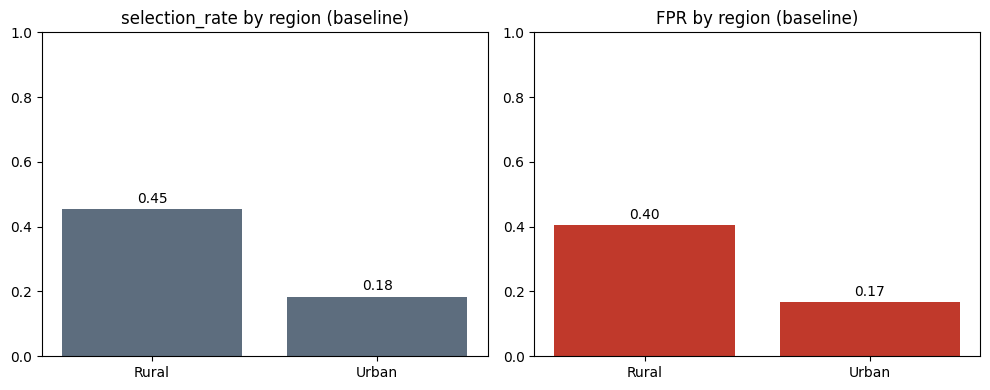

In [10]:
# ==== 6B. FAIRNESS METRICS (own implementation – transparent and reproducible) ====
def group_metrics(y, pred, groups):
    out = {}
    for g in sorted(pd.unique(groups)):
        m = (groups == g).values
        yt, yp = y.values[m], pred[m]
        neg, pos = (yt == 0), (yt == 1)
        out[g] = {"n": int(m.sum()), "selection_rate": yp.mean(),
                  "FPR": yp[neg].mean() if neg.any() else np.nan,
                  "TPR": yp[pos].mean() if pos.any() else np.nan,
                  "precision": (yt[yp==1].mean() if (yp==1).any() else np.nan)}
    return pd.DataFrame(out).T

def summary(tbl):
    sr, fpr, tpr = tbl["selection_rate"], tbl["FPR"], tbl["TPR"]
    return {"demographic_parity_diff": sr.max()-sr.min(),
            "disparate_impact_ratio": sr.min()/sr.max(),
            "adverse_flag_ratio (max/min)": sr.max()/sr.min(),
            "clear_rate_ratio (min/max)": (1-sr).min()/(1-sr).max(),
            "FPR_diff": fpr.max()-fpr.min(),
            "FPR_ratio (max/min)": fpr.max()/fpr.min(),
            "TPR_diff (equal opportunity)": tpr.max()-tpr.min(),
            "equalized_odds_diff": max(fpr.max()-fpr.min(), tpr.max()-tpr.min())}

R = {}   # results dictionary reused in the report
for attr in SENSITIVE:
    t = group_metrics(te.is_fraud, te_pred, te[attr])
    s = summary(t)
    R[f"base_{attr}_table"], R[f"base_{attr}_sum"] = t, s
    t.round(4).to_csv(f"{BASE}/outputs/baseline_metrics_by_{attr}.csv")
    print(f"\n=== Baseline by {attr} ==="); display(t.round(3))
    print({k: round(float(v),3) for k,v in s.items()})

# Bootstrap 95% CI for the FPR gap by region (uncertainty!)
rng_b = np.random.default_rng(SEED)
gaps = []
reg = te.region.values; yv = te.is_fraud.values
for _ in range(1000):
    i = rng_b.integers(0, len(te), len(te))
    r_, y_, p_ = reg[i], yv[i], te_pred[i]
    f = {g: p_[(r_==g)&(y_==0)].mean() for g in ["Rural","Urban"]}
    gaps.append(f["Rural"]-f["Urban"])
R["fpr_gap_ci"] = tuple(np.percentile(gaps, [2.5, 97.5]))
print("\nRural-minus-Urban FPR gap, 95% bootstrap CI:", np.round(R["fpr_gap_ci"], 3))

# Chart
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
t = R["base_region_table"]
for ax, m, c in zip(axes, ["selection_rate","FPR"], ["#5D6D7E","#C0392B"]):
    ax.bar(t.index, t[m], color=c); ax.set_title(f"{m} by region (baseline)"); ax.set_ylim(0, 1)
    for i, v in enumerate(t[m]): ax.text(i, v+0.02, f"{v:.2f}", ha="center")
plt.tight_layout(); plt.savefig(f"{BASE}/outputs/baseline_fpr_selection_by_region.png", dpi=150); plt.show()

## 7. Task 4 – Explainability and decision review
Three techniques: (1) global **permutation importance**, (2) **proxy analysis** (does the model "know" region without being told?), (3) **case review + counterfactual test** on rural false positives.

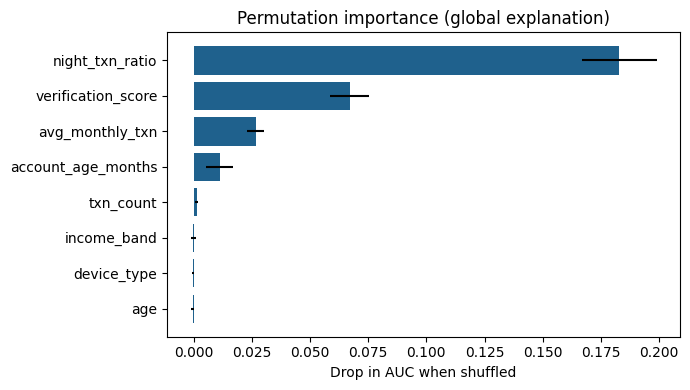

,feature,importance,std
4,night_txn_ratio,0.1829,0.0160
5,verification_score,0.0672,0.0084
2,avg_monthly_txn,0.0267,0.0037
1,account_age_months,0.0112,0.0057
3,txn_count,0.0014,0.0007
6,income_band,-0.0002,0.0011
7,device_type,-0.0003,0.0002
0,age,-0.0004,0.0008


,night_txn_ratio,verification_score,share_basic_phone
region,,,
Rural,0.271,0.780,0.600
Urban,0.200,0.847,0.201


Proxy test - AUC of predicting region from model inputs: 0.830 (0.5 = no leakage)


In [12]:
# ==== 7A. PERMUTATION IMPORTANCE ====
pi = permutation_importance(base, te[num+cat], te.is_fraud, scoring="roc_auc", n_repeats=15, random_state=SEED)
imp = pd.DataFrame({"feature": num+cat, "importance": pi.importances_mean, "std": pi.importances_std}).sort_values("importance", ascending=False)
imp.round(4).to_csv(f"{BASE}/outputs/permutation_importance.csv", index=False)
fig, ax = plt.subplots(figsize=(7, 4))
ax.barh(imp.feature[::-1], imp.importance[::-1], xerr=imp["std"][::-1], color="#1F618D")
ax.set_xlabel("Drop in AUC when shuffled"); ax.set_title("Permutation importance (global explanation)")
plt.tight_layout(); plt.savefig(f"{BASE}/outputs/permutation_importance.png", dpi=150); plt.show()
R["top_features"] = list(imp.feature[:3]); display(imp.round(4))

# ==== 7B. PROXY ANALYSIS ====
prox = df.groupby("region").agg(night_txn_ratio=("night_txn_ratio","mean"),
        verification_score=("verification_score","mean"),
        share_basic_phone=("device_type", lambda s: (s=="Basic").mean())).round(3)
display(prox)
# Can region be predicted from the non-sensitive features? (AUC >> 0.5 means proxies exist)
Xp = pd.get_dummies(df[num+cat], drop_first=True); yp_ = (df.region=="Rural").astype(int)
Xp_tr, Xp_te, yp_tr, yp_te = train_test_split(Xp, yp_, test_size=0.3, random_state=SEED, stratify=yp_)
proxy_clf = LogisticRegression(max_iter=2000).fit(StandardScaler().fit(Xp_tr).transform(Xp_tr), yp_tr)
sc = StandardScaler().fit(Xp_tr)
R["proxy_auc"] = roc_auc_score(yp_te, proxy_clf.predict_proba(sc.transform(Xp_te))[:,1])
print(f"Proxy test - AUC of predicting region from model inputs: {R['proxy_auc']:.3f} (0.5 = no leakage)")
prox.to_csv(f"{BASE}/outputs/proxy_feature_means_by_region.csv")

In [13]:
# ==== 7C. DECISION REVIEW: rural false positives + counterfactual ====
te2 = te.copy(); te2["score"] = te_score; te2["pred"] = te_pred
fp = te2[(te2.pred==1) & (te2.is_fraud==0)]
fp_rural = fp[fp.region=="Rural"]
print(f"False positives in test: {len(fp)} (Rural: {len(fp_rural)}, Urban: {len(fp)-len(fp_rural)})")

# per-case contribution = coefficient x transformed value
pre, clf = base.named_steps["pre"], base.named_steps["clf"]
names = list(pre.get_feature_names_out())
def top_reasons(rows, k=2):
    Xt = pre.transform(rows[num+cat]); Xt = Xt.toarray() if hasattr(Xt, "toarray") else Xt
    contrib = Xt * clf.coef_[0]
    return [", ".join(f"{names[j].split('__')[1]} ({contrib[i, j]:+.2f})" for j in np.argsort(-contrib[i])[:k]) for i in range(len(rows))]
case_review = fp_rural.sample(min(8, len(fp_rural)), random_state=SEED).copy()
case_review["top_reasons"] = top_reasons(case_review)
case_review = case_review[["customer_id","score","night_txn_ratio","verification_score","device_type","account_age_months","top_reasons"]].round(3)
case_review.to_csv(f"{BASE}/outputs/case_review_rural_false_positives.csv", index=False)
display(case_review)

# Counterfactual: change ONE feature at a time (and two together) to urban-typical values
urban_v = df[df.region=="Urban"].verification_score.median()
urban_n = df[df.region=="Urban"].night_txn_ratio.median()
def cf_share(mods):
    cf = fp_rural.copy()
    for k, v in mods.items(): cf[k] = v
    return 1 - (base.predict_proba(cf[num+cat])[:,1] >= THRESH).astype(int).mean()
cf_table = pd.DataFrame([
    ("Verification score set to urban median", cf_share({"verification_score": urban_v})),
    ("Device type set to smartphone", cf_share({"device_type": "Smartphone"})),
    ("Night-time transaction ratio set to urban median", cf_share({"night_txn_ratio": urban_n})),
    ("Verification score and device type together", cf_share({"verification_score": urban_v, "device_type": "Smartphone"}))],
    columns=["change", "share_no_longer_flagged"])
cf_table.round(3).to_csv(f"{BASE}/outputs/counterfactual_rural_false_positives.csv", index=False)
R["cf_table"] = cf_table; R["cf_flip_share"] = float(cf_table.iloc[3, 1])
print("Counterfactual (share of rural false positives no longer flagged):"); display(cf_table.round(3))
print("Note: changing features one at a time separates their contributions; it shows association within this model, not real-world causation.")

# Single-feature proxy strength: how well does each feature alone predict region?
from sklearn.metrics import roc_auc_score as _auc
isr = (df.region == "Rural").astype(int)
single = {c: _auc(isr, df[c]) for c in num}
single["device_type (basic phone)"] = _auc(isr, (df.device_type == "Basic").astype(int))
single = {k: max(v, 1-v) for k, v in single.items()}      # direction-free strength
R["proxy_single"] = dict(sorted(single.items(), key=lambda kv: -kv[1]))
R["imp"] = dict(zip(imp.feature, imp.importance))
pd.Series(R["proxy_single"]).round(3).to_csv(f"{BASE}/outputs/single_feature_region_auc.csv", header=["AUC"])
print("Single-feature region AUC:", {k: round(v, 2) for k, v in list(R["proxy_single"].items())[:4]})

False positives in test: 365 (Rural: 196, Urban: 169)


,customer_id,score,night_txn_ratio,verification_score,device_type,account_age_months,top_reasons
3880,SYN03880,0.900,0.397,0.685,Smartphone,27,"night_txn_ratio (+1.36), verification_score (+..."
4565,SYN04565,0.788,0.320,0.673,Basic,98,"verification_score (+1.31), night_txn_ratio (+..."
3071,SYN03071,0.625,0.233,0.671,Basic,46,"verification_score (+1.33), account_age_months..."
2435,SYN02435,0.506,0.134,0.617,Basic,73,"verification_score (+1.80), age (+0.02)"
2638,SYN02638,0.889,0.481,0.754,Basic,45,"night_txn_ratio (+2.01), verification_score (+..."
1218,SYN01218,0.606,0.255,0.831,Smartphone,60,"avg_monthly_txn (+0.95), night_txn_ratio (+0.25)"
1081,SYN01081,0.508,0.207,0.709,Basic,32,"verification_score (+1.00), account_age_months..."
4621,SYN04621,0.523,0.213,0.793,Basic,44,"avg_monthly_txn (+0.77), verification_score (+..."


Counterfactual (share of rural false positives no longer flagged):


,change,share_no_longer_flagged
0,Verification score set to urban median,0.531
1,Device type set to smartphone,0.000
2,Night-time transaction ratio set to urban median,0.658
3,Verification score and device type together,0.505


Note: changing features one at a time separates their contributions; it shows association within this model, not real-world causation.
Single-feature region AUC: {'verification_score': np.float64(0.72), 'device_type (basic phone)': np.float64(0.7), 'night_txn_ratio': np.float64(0.67), 'age': np.float64(0.5)}


## 8. Task 4 – Mitigation and re-evaluation
Three options compared, all re-measured on the **same untouched test set**:
1. **M1 – Remove proxy features** (`device_type`, `verification_score`).
2. **M2 – Reweight training data** so that genuine (non-fraud) rural and urban customers carry equal total weight (reduces rural over-flagging).
3. **M3 – Group-specific thresholds** tuned on the *validation* set so group FPRs match. ⚠️ Using a protected attribute at decision time may itself raise legal/ethical concerns.

M3 thresholds: {'Urban': np.float64(0.495), 'Rural': np.float64(0.701)} | target FPR: 0.164


,FPR_rural,FPR_urban,FPR_ratio,DI_ratio,Flag_ratio,Clear_ratio,TPR_diff,EO_diff,recall,precision,accuracy
Model,,,,,,,,,,,
Baseline,0.404,0.167,2.427,0.405,2.468,0.669,0.211,0.238,0.77,0.174,0.758
M1 drop proxies,0.351,0.224,1.567,0.611,1.636,0.796,0.027,0.127,0.76,0.161,0.737
M2 reweighting,0.126,0.052,2.409,0.358,2.792,0.882,0.233,0.233,0.45,0.283,0.894
M3 group thresholds,0.184,0.169,1.083,0.804,1.244,0.944,0.018,0.018,0.63,0.194,0.814


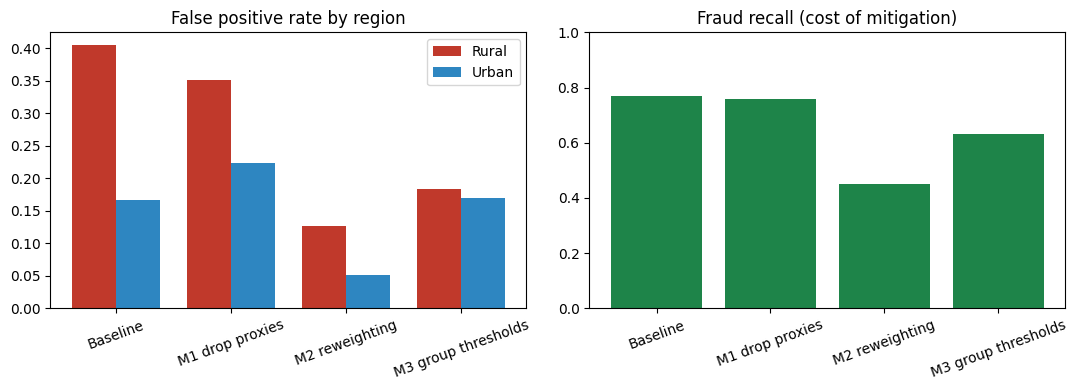

Gender baseline summary: {'demographic_parity_diff': 0.034, 'disparate_impact_ratio': 0.885, 'adverse_flag_ratio (max/min)': 1.129, 'clear_rate_ratio (min/max)': 0.955, 'FPR_diff': 0.03, 'FPR_ratio (max/min)': 1.133, 'TPR_diff (equal opportunity)': 0.1, 'equalized_odds_diff': 0.1}
Note: gender TPR gap rests on few fraud cases per group - check the confidence interval before drawing conclusions.


In [14]:
# ==== 8. MITIGATION ====
results = {"Baseline": (te_pred, te_score)}

# M1: drop proxies
num_m1 = [c for c in num if c != "verification_score"]; cat_m1 = [c for c in cat if c != "device_type"]
m1 = make_pipe(num_m1, cat_m1).fit(tr[num_m1+cat_m1], tr.is_fraud)
s1 = m1.predict_proba(te[num_m1+cat_m1])[:,1]; results["M1 drop proxies"] = ((s1>=THRESH).astype(int), s1)

# M2: reweight (non-fraud rural up-weighted so groups contribute equally among genuine customers)
w = np.ones(len(tr))
neg_r = ((tr.region=="Rural") & (tr.is_fraud==0)).values; neg_u = ((tr.region=="Urban") & (tr.is_fraud==0)).values
w[neg_r] = neg_u.sum() / neg_r.sum() * 2.0     # factor documented: tune on validation data
# Class-balance weights are computed explicitly (class_weight=None) so the result does not depend on how a
# particular scikit-learn version combines class_weight='balanced' with sample_weight.
y_tr = tr.is_fraud.values; n_tr = len(y_tr)
cw_vec = np.where(y_tr == 1, n_tr/(2*y_tr.sum()), n_tr/(2*(n_tr - y_tr.sum())))
m2 = make_pipe(num, cat, class_weight=None); m2.fit(tr[num+cat], tr.is_fraud, clf__sample_weight=w*cw_vec)
s2 = m2.predict_proba(te[num+cat])[:,1]; results["M2 reweighting"] = ((s2>=THRESH).astype(int), s2)

# M3: group thresholds on validation set, target = baseline Urban FPR
va_score = base.predict_proba(va[num+cat])[:,1]
target = ((va_score >= THRESH) & (va.is_fraud==0) & (va.region=="Urban")).sum() / ((va.is_fraud==0) & (va.region=="Urban")).sum()
thr = {}
for g in ["Urban","Rural"]:
    negs = np.sort(va_score[((va.is_fraud==0)&(va.region==g)).values])
    thr[g] = np.quantile(negs, 1-target)
p3 = np.where(te.region=="Rural", te_score>=thr["Rural"], te_score>=thr["Urban"]).astype(int)
results["M3 group thresholds"] = (p3, te_score)
print("M3 thresholds:", {k: round(v,3) for k,v in thr.items()}, "| target FPR:", round(target,3))

rows = []
for name, (p, s) in results.items():
    t = group_metrics(te.is_fraud, p, te.region); sm = summary(t); pf = perf(te.is_fraud, p, s)
    rows.append({"Model": name, "FPR_rural": t.loc["Rural","FPR"], "FPR_urban": t.loc["Urban","FPR"],
                 "FPR_ratio": sm["FPR_ratio (max/min)"], "DI_ratio": sm["disparate_impact_ratio"],
                 "Flag_ratio": sm["adverse_flag_ratio (max/min)"], "Clear_ratio": sm["clear_rate_ratio (min/max)"],
                 "TPR_diff": sm["TPR_diff (equal opportunity)"], "EO_diff": sm["equalized_odds_diff"],
                 "recall": pf["recall"], "precision": pf["precision"], "accuracy": pf["accuracy"]})
comp = pd.DataFrame(rows).set_index("Model").round(3)
comp.to_csv(f"{BASE}/outputs/mitigation_comparison.csv"); R["comp"] = comp
display(comp)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
x = np.arange(len(comp)); w_ = 0.38
axes[0].bar(x-w_/2, comp.FPR_rural, w_, label="Rural", color="#C0392B"); axes[0].bar(x+w_/2, comp.FPR_urban, w_, label="Urban", color="#2E86C1")
axes[0].set_xticks(x); axes[0].set_xticklabels(comp.index, rotation=20); axes[0].set_title("False positive rate by region"); axes[0].legend()
axes[1].bar(x, comp.recall, color="#1E8449"); axes[1].set_xticks(x); axes[1].set_xticklabels(comp.index, rotation=20)
axes[1].set_title("Fraud recall (cost of mitigation)"); axes[1].set_ylim(0,1)
plt.tight_layout(); plt.savefig(f"{BASE}/outputs/mitigation_comparison.png", dpi=150); plt.show()

# Second attribute (gender) check on baseline
print("Gender baseline summary:", {k: round(float(v),3) for k,v in R["base_gender_sum"].items()})
print("Note: gender TPR gap rests on few fraud cases per group - check the confidence interval before drawing conclusions.")

## 9. Task 5 – Professional Report

In [15]:
# ==== 9. BUILD PROFESSIONAL WORD REPORT ====
!pip install -q python-docx
import re, datetime
from docx import Document
from docx.shared import Pt, Cm, RGBColor
from docx.enum.text import WD_ALIGN_PARAGRAPH
from docx.enum.table import WD_TABLE_ALIGNMENT, WD_CELL_VERTICAL_ALIGNMENT
from docx.enum.section import WD_ORIENT, WD_SECTION
from docx.oxml.ns import qn
from docx.oxml import OxmlElement
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch

# ---------- EDIT THESE ----------
STUDENT_NAME = "Asim Shayan Khan"
REG_NO       = "2026/AICDF/16715"
COHORT       = "1"
GITHUB_URL   = "[paste your GitHub repository URL here]"
# --------------------------------

NAVY, BLUE, LIGHT, GREY = "1F4E79", "2E75B6", "EAF1F8", "595959"
FIG = f"{BASE}/outputs"

# ================= EXTRA FIGURES =================
def make_pipeline_fig():
    steps = ["Data inputs\n(ID, biometrics,\ndevice, transactions)", "Identity\nverification", "Fraud\ndetection",
             "Risk\nscoring", "Recommend-\nation", "Human\nreview", "Customer outcome\nand appeal"]
    ctrl = ["Minimise data;\nlawful basis", "Non-biometric\nfallback", "Group bias\ntesting", "Explainability\nchecks",
            "Reason codes", "Override\nlogging", "Appeal decision\nwithin 48 hours"]
    cols = ["#1F4E79"]*5 + ["#2E8B57", "#7F8C8D"]
    fig, ax = plt.subplots(figsize=(11, 2.9)); ax.axis("off"); ax.set_xlim(0, 11); ax.set_ylim(0, 3)
    for i, (s, c, k) in enumerate(zip(steps, ctrl, cols)):
        x = 0.15 + i*1.55
        ax.add_patch(FancyBboxPatch((x, 1.45), 1.3, 1.2, boxstyle="round,pad=0.03", fc=k, ec="none"))
        ax.text(x+0.65, 2.05, s, ha="center", va="center", color="white", fontsize=7.5, fontweight="bold")
        ax.text(x+0.65, 0.95, c, ha="center", va="center", fontsize=7, color="#333333", style="italic")
        ax.add_patch(FancyBboxPatch((x, 0.5), 1.3, 0.9, boxstyle="round,pad=0.02", fc="#EAF1F8", ec="#9DB7D5", lw=0.6, zorder=0))
        if i < 6: ax.add_patch(FancyArrowPatch((x+1.33, 2.05), (x+1.52, 2.05), arrowstyle="-|>", mutation_scale=9, color="#444"))
    ax.text(0.15, 0.2, "Top row: system stages.  Shaded row: proposed control point at each stage.", fontsize=7, color="#555")
    plt.tight_layout(); plt.savefig(f"{FIG}/system_pipeline.png", dpi=200); plt.close()

def make_heatmap_fig():
    fig, axes = plt.subplots(1, 2, figsize=(10, 4.4))
    for ax, (lcol, icol, title) in zip(axes, [("Likelihood (1-5)", "Impact (1-5)", "Inherent risk (before controls)"),
                                              ("Residual likelihood", "Residual impact", "Residual risk (after controls)")]):
        for L in range(1, 6):
            for I in range(1, 6):
                s = L*I; c = "#C6E0B4" if s < 8 else ("#FFE699" if s < 15 else "#F4B6B6")
                ax.add_patch(plt.Rectangle((L-0.5, I-0.5), 1, 1, fc=c, ec="white", lw=1.5))
        for (L, I), ids in rr.groupby([lcol, icol])["ID"].apply(list).items():
            ax.text(L, I, "\n".join(", ".join(ids[i:i+2]) for i in range(0, len(ids), 2)), ha="center", va="center", fontsize=7.5, fontweight="bold")
        ax.set_xlim(0.5, 5.5); ax.set_ylim(0.5, 5.5); ax.set_xticks(range(1, 6)); ax.set_yticks(range(1, 6))
        ax.set_xlabel("Likelihood"); ax.set_ylabel("Impact"); ax.set_title(title, fontsize=10)
    plt.tight_layout(); plt.savefig(f"{FIG}/risk_heatmaps.png", dpi=200); plt.close()
make_pipeline_fig(); make_heatmap_fig()

# ================= DOCX HELPERS =================
doc = Document()
sec = doc.sections[0]
sec.page_width, sec.page_height = Cm(21), Cm(29.7)
for s_ in ("left_margin", "right_margin"): setattr(sec, s_, Cm(2.2))
sec.top_margin, sec.bottom_margin = Cm(2.3), Cm(2.0)
sec.different_first_page_header_footer = True

def set_style_font(style, name, size, bold=None, color=None, italic=None):
    style.font.name = name; style.font.size = Pt(size)
    if bold is not None: style.font.bold = bold
    if italic is not None: style.font.italic = italic
    if color: style.font.color.rgb = RGBColor.from_string(color)
    rpr = style.element.get_or_add_rPr(); rf = rpr.find(qn("w:rFonts"))
    if rf is None: rf = OxmlElement("w:rFonts"); rpr.append(rf)
    for a in ("w:ascii", "w:hAnsi", "w:eastAsia", "w:cs"): rf.set(qn(a), name)
    for a in ("w:asciiTheme", "w:hAnsiTheme", "w:eastAsiaTheme", "w:cstheme"):
        if rf.get(qn(a)) is not None: del rf.attrib[qn(a)]

def para_border(p_pr_parent, side="bottom", color=BLUE, sz=8, space=2):
    if hasattr(p_pr_parent, "_p"): p_pr_parent = p_pr_parent._p
    pPr = p_pr_parent.get_or_add_pPr(); b = OxmlElement("w:pBdr"); e = OxmlElement(f"w:{side}")
    e.set(qn("w:val"), "single"); e.set(qn("w:sz"), str(sz)); e.set(qn("w:space"), str(space)); e.set(qn("w:color"), color)
    b.append(e); pPr.append(b)

st = doc.styles
set_style_font(st["Normal"], "Calibri", 10.5)
st["Normal"].paragraph_format.space_after = Pt(6); st["Normal"].paragraph_format.line_spacing = 1.15
set_style_font(st["Heading 1"], "Calibri", 16, True, NAVY)
st["Heading 1"].paragraph_format.space_before = Pt(18); st["Heading 1"].paragraph_format.space_after = Pt(8)
st["Heading 1"].paragraph_format.keep_with_next = True; para_border(st["Heading 1"].element, "bottom", BLUE, 12, 3)
set_style_font(st["Heading 2"], "Calibri", 12.5, True, BLUE)
st["Heading 2"].paragraph_format.space_before = Pt(12); st["Heading 2"].paragraph_format.space_after = Pt(4)
st["Heading 2"].paragraph_format.keep_with_next = True
set_style_font(st["List Bullet"], "Calibri", 10.5); set_style_font(st["List Number"], "Calibri", 10.5)
for nm in ("List Bullet", "List Number"): st[nm].paragraph_format.space_after = Pt(3)

WC = {"on": False, "n": 0, "tab": 0}
def count_words(t):
    if WC["on"]: WC["n"] += len(re.sub(r"\*\*", "", t).split())

def add_runs(p, text, size=None, color=None, italic=False, bold_all=False):
    for part in re.split(r"(\*\*.+?\*\*)", text):
        if not part: continue
        b = part.startswith("**"); r = p.add_run(part[2:-2] if b else part)
        r.bold = b or bold_all; r.italic = italic
        if size: r.font.size = Pt(size)
        if color: r.font.color.rgb = RGBColor.from_string(color)

def H1(t): doc.add_heading(t, level=1)
def H2(t): doc.add_heading(t, level=2)
def P(t, align="justify", after=6):
    p = doc.add_paragraph(); add_runs(p, t); count_words(t)
    p.alignment = WD_ALIGN_PARAGRAPH.JUSTIFY if align == "justify" else WD_ALIGN_PARAGRAPH.LEFT
    p.paragraph_format.space_after = Pt(after); return p
def BUL(t, style="List Bullet"):
    p = doc.add_paragraph(style=style); add_runs(p, t); count_words(t); return p

def shade(cell, fill):
    tcPr = cell._tc.get_or_add_tcPr()
    for old_ in tcPr.findall(qn("w:shd")): tcPr.remove(old_)
    sh = OxmlElement("w:shd")
    sh.set(qn("w:val"), "clear"); sh.set(qn("w:color"), "auto"); sh.set(qn("w:fill"), fill); tcPr.append(sh)

def cell_margins(tbl, top=50, bottom=50, left=90, right=90):
    tblPr = tbl._tbl.tblPr; m = OxmlElement("w:tblCellMar")
    for k, v in (("top", top), ("left", left), ("bottom", bottom), ("right", right)):
        e = OxmlElement(f"w:{k}"); e.set(qn("w:w"), str(v)); e.set(qn("w:type"), "dxa"); m.append(e)
    tblPr.append(m)

def table_borders(tbl, color="B7C9DD"):
    tblPr = tbl._tbl.tblPr; b = OxmlElement("w:tblBorders")
    for k in ("top", "left", "bottom", "right", "insideH", "insideV"):
        e = OxmlElement(f"w:{k}"); e.set(qn("w:val"), "single"); e.set(qn("w:sz"), "4"); e.set(qn("w:space"), "0"); e.set(qn("w:color"), color); b.append(e)
    tblPr.append(b)

RATING_FILL = {"High": "F4B6B6", "Medium": "FFE699", "Low": "C6E0B4"}
def TABLE(headers, rows, widths, font=8.5, center=(), rating_cols=(), first_col_bold=False, space_after=8):
    t = doc.add_table(rows=1, cols=len(headers)); t.alignment = WD_TABLE_ALIGNMENT.CENTER; t.autofit = False
    tblPr = t._tbl.tblPr   # t.autofit = False already writes <w:tblLayout w:type="fixed"/>
    table_borders(t); cell_margins(t)
    for i, w_ in enumerate(widths): t.columns[i].width = Cm(w_)
    for i, h in enumerate(headers):
        c = t.rows[0].cells[i]; c.width = Cm(widths[i]); shade(c, NAVY); c.vertical_alignment = WD_CELL_VERTICAL_ALIGNMENT.CENTER
        p = c.paragraphs[0]; p.alignment = WD_ALIGN_PARAGRAPH.CENTER; p.paragraph_format.space_after = Pt(0)
        r = p.add_run(str(h)); r.bold = True; r.font.size = Pt(font); r.font.color.rgb = RGBColor(255, 255, 255)
    trPr = t.rows[0]._tr.get_or_add_trPr(); th = OxmlElement("w:tblHeader"); th.set(qn("w:val"), "true"); trPr.append(th)
    for ri, row in enumerate(rows):
        cells = t.add_row().cells
        cs = OxmlElement("w:cantSplit"); t.rows[-1]._tr.get_or_add_trPr().append(cs)
        for i, v in enumerate(row):
            c = cells[i]; c.width = Cm(widths[i]); c.vertical_alignment = WD_CELL_VERTICAL_ALIGNMENT.CENTER
            if ri % 2 == 1: shade(c, "F3F7FB")
            if i in rating_cols and str(v) in RATING_FILL: shade(c, RATING_FILL[str(v)])
            p = c.paragraphs[0]; p.paragraph_format.space_after = Pt(0); p.paragraph_format.line_spacing = 1.0
            if i in center or i in rating_cols: p.alignment = WD_ALIGN_PARAGRAPH.CENTER
            add_runs(p, str(v), size=font, bold_all=(first_col_bold and i == 0))
    if WC["on"]: WC["tab"] += sum(len(re.sub(r"\*\*", "", str(x)).split()) for x in list(headers) + [c for rw in rows for c in rw])
    for old_ in tblPr.findall(qn("w:tblW")): tblPr.remove(old_)
    tw = OxmlElement("w:tblW"); tw.set(qn("w:w"), str(int(sum(widths) * 567))); tw.set(qn("w:type"), "dxa"); tblPr.append(tw)
    sp = doc.add_paragraph(); sp.paragraph_format.space_after = Pt(space_after); sp.paragraph_format.space_before = Pt(0)
    return t

def CALLOUT(title, text, fill="FFF4D6", edge="C9A227"):
    t = doc.add_table(rows=1, cols=1); t.alignment = WD_TABLE_ALIGNMENT.CENTER; t.autofit = False
    t.columns[0].width = Cm(16.6); c = t.rows[0].cells[0]; c.width = Cm(16.6); shade(c, fill); cell_margins(t, 100, 100, 160, 160)
    tcPr = c._tc.get_or_add_tcPr(); b = OxmlElement("w:tcBorders")
    for side, sz, col in (("top", 4, edge), ("left", 24, edge), ("bottom", 4, edge), ("right", 4, edge)):
        e = OxmlElement(f"w:{side}"); e.set(qn("w:val"), "single"); e.set(qn("w:sz"), str(sz)); e.set(qn("w:color"), col); b.append(e)
    tcPr.append(b)
    p = c.paragraphs[0]; add_runs(p, f"**{title}**  " + text, size=9.5); p.alignment = WD_ALIGN_PARAGRAPH.JUSTIFY
    p.paragraph_format.space_after = Pt(0); count_words(title + " " + text)
    sp = doc.add_paragraph(); sp.paragraph_format.space_after = Pt(4)

FIGN = {"s": 0, "n": 0}
def FIGURE(path, caption, width=15.0):
    doc.add_picture(path, width=Cm(width)); doc.paragraphs[-1].alignment = WD_ALIGN_PARAGRAPH.CENTER
    doc.paragraphs[-1].paragraph_format.keep_with_next = True; doc.paragraphs[-1].paragraph_format.space_after = Pt(2)
    cp = doc.add_paragraph(); add_runs(cp, caption, size=8.5, color=GREY, italic=True)
    cp.alignment = WD_ALIGN_PARAGRAPH.CENTER; cp.paragraph_format.space_after = Pt(10)

def TCAP(caption):
    # caption is written after the table call, then moved above that table
    cp = doc.add_paragraph(); add_runs(cp, caption, size=8.5, color=GREY, italic=True)
    cp.alignment = WD_ALIGN_PARAGRAPH.CENTER; cp.paragraph_format.keep_with_next = True
    cp.paragraph_format.space_before = Pt(6); cp.paragraph_format.space_after = Pt(3)
    tbls = [e for e in doc.element.body if e.tag == qn("w:tbl")]
    tbls[-1].addprevious(cp._p)

def add_field(run, instr):
    for typ, txt in (("begin", None), (None, instr), ("separate", None), ("t", "1"), ("end", None)):
        if typ in ("begin", "separate", "end"):
            e = OxmlElement("w:fldChar"); e.set(qn("w:fldCharType"), typ)
        elif typ == "t":
            e = OxmlElement("w:t"); e.text = txt
        else:
            e = OxmlElement("w:instrText"); e.set(qn("xml:space"), "preserve"); e.text = txt
        run._r.append(e)

def new_section(landscape):
    s = doc.add_section(WD_SECTION.NEW_PAGE)
    if landscape: s.orientation = WD_ORIENT.LANDSCAPE; s.page_width, s.page_height = Cm(29.7), Cm(21)
    else: s.orientation = WD_ORIENT.PORTRAIT; s.page_width, s.page_height = Cm(21), Cm(29.7)
    s.left_margin = s.right_margin = Cm(2.2); s.top_margin = Cm(2.3); s.bottom_margin = Cm(2.0)
    s.different_first_page_header_footer = False
    return s

# header / footer (not on cover)
hp = sec.header.paragraphs[0]; hp.alignment = WD_ALIGN_PARAGRAPH.RIGHT
add_runs(hp, "AI Ethics, Governance and Compliance  |  SecureFinance Africa Assessment", size=8.5, color=GREY)
para_border(hp, "bottom", "BFBFBF", 4, 4)
fp = sec.footer.paragraphs[0]; fp.alignment = WD_ALIGN_PARAGRAPH.CENTER
for txt, fld in (("Page ", None), (None, "PAGE"), (" of ", None), (None, "NUMPAGES")):
    r = fp.add_run(txt or ""); r.font.size = Pt(8.5); r.font.color.rgb = RGBColor.from_string(GREY)
    if fld: add_field(r, fld)
ffp = sec.first_page_footer.paragraphs[0]; ffp.alignment = WD_ALIGN_PARAGRAPH.CENTER
add_runs(ffp, "Synthetic data only  |  Fictional organisation  |  For academic assessment use only", size=8.5, color=GREY, italic=True)

doc.core_properties.title = "AI Ethics, Governance and Compliance Assessment - SecureFinance Africa"
doc.core_properties.author = STUDENT_NAME


# ---------- schema-order normalisation so Word opens the file without repair ----------
TBLPR = ["tblStyle","tblpPr","tblOverlap","bidiVisual","tblStyleRowBandSize","tblStyleColBandSize","tblW","jc","tblCellSpacing","tblInd","tblBorders","shd","tblLayout","tblCellMar","tblLook"]
TCPR = ["cnfStyle","tcW","gridSpan","hMerge","vMerge","tcBorders","shd","noWrap","tcMar","textDirection","tcFitText","vAlign","hideMark"]
PPR = ["pStyle","keepNext","keepLines","pageBreakBefore","framePr","widowControl","numPr","suppressLineNumbers","pBdr","shd","tabs","suppressAutoHyphens","kinsoku","wordWrap","overflowPunct","topLinePunct","autoSpaceDE","autoSpaceDN","bidi","adjustRightInd","snapToGrid","spacing","ind","contextualSpacing","mirrorIndents","suppressOverlap","jc","textDirection","textAlignment","textboxTightWrap","outlineLvl","divId","cnfStyle","rPr","sectPr","pPrChange"]
def _reorder(el, order):
    kids = list(el); name = lambda e: e.tag.split("}")[1]
    kids.sort(key=lambda e: order.index(name(e)) if name(e) in order else 99)
    for k in kids: el.remove(k)
    for k in kids: el.append(k)
def normalise(root):
    for e in root.iter(qn("w:tblPr")): _reorder(e, TBLPR)
    for e in root.iter(qn("w:tcPr")): _reorder(e, TCPR)
    for e in root.iter(qn("w:pPr")): _reorder(e, PPR)
def normalise_document(d):
    for z in d.settings.element.iter(qn("w:zoom")): z.set(qn("w:percent"), "100")
    normalise(d.element.body); normalise(d.styles.element)
    for s_ in d.sections:
        for part in (s_.header, s_.footer, s_.first_page_header, s_.first_page_footer): normalise(part._element)

# ================= NUMBERS USED IN TEXT =================
fmt_counts = lambda s: " and ".join(f"{v} {k}" for k, v in s.value_counts().reindex(["High", "Medium", "Low"]).dropna().astype(int).items())
bt, comp = R["base_region_table"], R["comp"]; gt = R["base_gender_table"]
fr, fu = bt.loc["Rural", "FPR"], bt.loc["Urban", "FPR"]
sr_r, sr_u = bt.loc["Rural", "selection_rate"], bt.loc["Urban", "selection_rate"]
tpr_r, tpr_u = bt.loc["Rural", "TPR"], bt.loc["Urban", "TPR"]
S = R["base_region_sum"]; G = R["base_gender_sum"]
fratio, flag_ratio, clear_ratio = S["FPR_ratio (max/min)"], S["adverse_flag_ratio (max/min)"], S["clear_rate_ratio (min/max)"]
lo, hi = R["fpr_gap_ci"]; b = comp.loc["Baseline"]
n_high_in, n_high_out = int((rr["Inherent rating"] == "High").sum()), int((rr["Residual rating"] == "High").sum())
opts = [n for n in comp.index if n != "Baseline"]
meets = [n for n in opts if comp.loc[n, "FPR_ratio"] <= 1.25]
fraud_reg = df.groupby("region").is_fraud.mean()
today = datetime.date.today().strftime("%d %B %Y")
LBL = {"M1 drop proxies": "Removing the proxy features", "M2 reweighting": "Reweighting", "M3 group thresholds": "Group-specific thresholds"}
def mit_sentence(n):
    r = comp.loc[n]
    return f"{LBL[n]} gave a false positive ratio of {r['FPR_ratio']:.2f} (rural {r['FPR_rural']:.3f}, urban {r['FPR_urban']:.3f}) with fraud recall of {r['recall']:.2f}"
best_txt = (f"Only {', '.join(LBL[m].lower() for m in meets)} brought the false positive ratio to the proposed 1.25 limit" if meets
            else "None of the single mitigations tested reached the proposed 1.25 limit")
cf = R["cf_table"].set_index("change")["share_no_longer_flagged"]
cf_v, cf_d, cf_n, cf_b = cf.iloc[0], cf.iloc[1], cf.iloc[2], cf.iloc[3]
ps = list(R["proxy_single"].items())[:3]
dev_basic_r = (df[df.region == "Rural"].device_type == "Basic").mean(); dev_basic_u = (df[df.region == "Urban"].device_type == "Basic").mean()

# ================= COVER PAGE =================
doc.add_paragraph()
p = doc.add_paragraph(); add_runs(p, "INTERNATIONAL CYBERSECURITY & DIGITAL FORENSICS ACADEMY", size=11, color=NAVY, bold_all=True); p.alignment = WD_ALIGN_PARAGRAPH.CENTER
p = doc.add_paragraph(); add_runs(p, "ICDFA  ·  AI-Driven Cybersecurity and Digital Forensics Fellowship", size=10, color=GREY); p.alignment = WD_ALIGN_PARAGRAPH.CENTER
para_border(p, "bottom", NAVY, 18, 8)
doc.add_paragraph()
p = doc.add_paragraph(); add_runs(p, "A S S E S S M E N T   R E P O R T", size=11, color=BLUE, bold_all=True); p.alignment = WD_ALIGN_PARAGRAPH.CENTER
t = doc.add_table(rows=1, cols=1); t.alignment = WD_TABLE_ALIGNMENT.CENTER; t.columns[0].width = Cm(16.6); c = t.rows[0].cells[0]; c.width = Cm(16.6); shade(c, NAVY); cell_margins(t, 260, 260, 240, 240)
p = c.paragraphs[0]; p.alignment = WD_ALIGN_PARAGRAPH.CENTER; add_runs(p, "AI Ethics, Governance and Compliance Assessment", size=26, color="FFFFFF", bold_all=True)
p2 = c.add_paragraph(); p2.alignment = WD_ALIGN_PARAGRAPH.CENTER
add_runs(p2, "Independent pre-deployment assessment of the SecureFinance Africa AI platform for identity verification, fraud detection and financial risk assessment", size=12, color="DCE6F2")
doc.add_paragraph()
rows_c = [("Name", STUDENT_NAME), ("Registration number", REG_NO), ("Cohort", COHORT),
          ("Role", "Independent AI Ethics, Governance and Compliance Analyst"),
          ("Organisation assessed", "SecureFinance Africa (fictional financial technology organisation)"),
          ("Compute and tools", "Google Colab (Python 3, scikit-learn, pandas, matplotlib); fixed random seed 42"),
          ("Data used", f"Synthetic dataset of {len(df):,} fictional customer records generated for this assessment"),
          ("Code and evidence repository", GITHUB_URL), ("AI assistance", "Declared in Appendix E"), ("Date", today)]
ct = doc.add_table(rows=0, cols=2); ct.alignment = WD_TABLE_ALIGNMENT.CENTER; ct.autofit = False; table_borders(ct, "D0D9E4"); cell_margins(ct, 60, 60, 120, 120)
for k, v in rows_c:
    cs = ct.add_row().cells; cs[0].width, cs[1].width = Cm(4.6), Cm(11.4); shade(cs[0], LIGHT)
    for c_, txt, bold in ((cs[0], k, True), (cs[1], v, False)):
        pp = c_.paragraphs[0]; pp.paragraph_format.space_after = Pt(0); add_runs(pp, txt, size=10, bold_all=bold, color=NAVY if bold else None)
ct.columns[0].width, ct.columns[1].width = Cm(4.6), Cm(11.4)
for _ in range(2): doc.add_paragraph()
p = doc.add_paragraph(); add_runs(p, "Defensive AI  ·  Synthetic Data  ·  For Academic and Research Use Only", size=9.5, color=GREY, italic=True); p.alignment = WD_ALIGN_PARAGRAPH.CENTER
doc.add_page_break()

# ================= CONTENTS =================
H1("Contents")
toc = ["1. Executive Summary", "2. System Description, Scope and Assumptions", "3. Ethical Risk Assessment",
       "4. AI Governance and Risk Management (NIST AI RMF)", "5. Legal and Regulatory Compliance", "6. Algorithmic Fairness and Explainability",
       "7. Prioritised Recommendations", "8. Deployment Recommendation", "9. References",
       "Appendix A: Ethical Risk Analysis", "Appendix B: AI Risk Register", "Appendix C: Supplementary Fairness Results",
       "Appendix D: Assumptions and Limitations", "Appendix E: AI-Assistance Declaration", "Appendix F: Repository and Reproducibility"]
for line in toc:
    p = doc.add_paragraph(); add_runs(p, line, size=11, bold_all=not line.startswith("Appendix"), color=NAVY if not line.startswith("Appendix") else None)
    p.paragraph_format.space_after = Pt(3)
doc.add_page_break()

# ================= 1. EXECUTIVE SUMMARY =================
WC["on"] = True
H1("1. Executive Summary")
P("SecureFinance Africa proposes to deploy an AI platform in Nigeria that verifies customer identity, detects fraud and recommends financial risk decisions. This independent pre-deployment assessment prioritises ethical risks, applies the NIST AI Risk Management Framework (AI RMF 1.0), separates binding law from voluntary principles, and tests fairness on a documented synthetic example.")
P(f"Seven ethical risks and an eleven-entry risk register were produced. Before controls the register rates {fmt_counts(rr['Inherent rating'])}; after the proposed controls it rates {fmt_counts(rr['Residual rating'])}{', with none remaining High' if n_high_out == 0 else ''}. The most serious concern is harm to genuine customers from wrongful fraud flags, because it falls on people least able to absorb a loss of access to their money.")
P(f"The synthetic fairness test supports that concern. The baseline model flagged **{fr:.1%}** of genuine rural customers against **{fu:.1%}** of genuine urban customers (ratio {fratio:.2f}; 95 percent bootstrap interval for the gap {lo:.2f} to {hi:.2f}), although region was never a model input. Rural customers were flagged {flag_ratio:.2f} times as often overall, and the share left unflagged was {clear_ratio:.2f} of the urban share, below the adapted 0.8 screening threshold (a United States rule of thumb, not a Nigerian legal test). Region could be predicted from the model inputs with an AUC of {R['proxy_auc']:.2f}. {best_txt}.")
P("The Nigeria Data Protection Act 2023 and the NDPC's 2025 implementing directive apply from the first day of a Nigerian deployment. The EU AI Act applies only if the system is placed on the EU market or its output is used there, so it would matter on expansion but not at launch. UNESCO and OECD instruments are voluntary benchmarks.")
P("**Recommendation: conditional, phased deployment.** The platform should not launch at scale until the conditions in Section 8 are met. It should begin as a supervised pilot with mandatory human review of every adverse decision, an appeal route, live fairness monitoring and clear rollback triggers.")
TABLE(["Headline result", "Value"], [
    ["Ethical risks assessed / register risks", "7 / 11"],
    ["High-rated register risks (inherent, then residual)", f"{n_high_in}, then {n_high_out}"],
    ["False positive rate: rural vs urban (baseline)", f"{fr:.1%} vs {fu:.1%} (ratio {fratio:.2f})"],
    ["Flag-rate ratio, rural to urban (baseline)", f"{flag_ratio:.2f}"],
    ["Share-not-flagged ratio, adapted four-fifths screen (baseline)", f"{clear_ratio:.2f} (screening threshold 0.80)"],
    ["Mitigation reaching a false positive ratio of 1.25 or better", ", ".join(LBL[m] for m in meets) if meets else "None as a single option"],
    ["Deployment decision", "Conditional, phased pilot"]], [9.8, 6.8], font=9, first_col_bold=True)
TCAP("Table 1.1: Summary of headline results")

# ================= 2. SYSTEM DESCRIPTION =================
H1("2. System Description, Scope and Assumptions")
H2("2.1 System description")
P("The platform ingests identity data, biometric verification inputs, device information and transaction histories. It verifies identity, scores transactions for fraud, estimates financial risk and recommends actions such as approve, step-up verification, hold or decline. Because these recommendations can restrict access to money, the system is treated as high-impact throughout. Stakeholders include customers, review staff, the model owner, vendors and regulators. The model boundary is the recommendation: a trained reviewer, not the model, takes the final adverse decision.")
FIGURE(f"{FIG}/system_pipeline.png", "Figure 2.1: Decision pipeline and proposed control point at each stage", 16.2)
H2("2.2 Scope and assumptions")
P("The assessment covers pre-deployment design, proposed governance and the fairness behaviour of a representative model. It does not assess any live system, and no third-party service was tested. The following assumptions are used consistently:")
for a in ["Deployment is in Nigeria only at launch, with possible later expansion to the EU or other markets.",
          "Data subjects are Nigerian residents, some of whom may be foreign nationals.",
          "SecureFinance acts as data controller; cloud and identity-verification vendors act as processors.",
          "The system uses identity numbers, biometric verification and transaction data, and biometrics are treated as sensitive data.",
          "The model recommends and trained humans take the final adverse decision. Governance must prove this holds in practice.",
          "Financial-sector rules such as central bank KYC and consumer-protection requirements also apply and are outside the detailed scope here."]: BUL(a)
H2("2.3 Approach")
P(f"Ethical risks were mapped to NIST, UNESCO and OECD principles; governance and a risk register were built around the four NIST functions; legal applicability was analysed against the stated assumptions; and a reproducible Python analysis of {len(df):,} synthetic records measured fairness, explained model behaviour and tested mitigations (Appendix F).")

# ================= 3. ETHICAL RISKS =================
H1("3. Ethical Risk Assessment")
P("Seven ethical risks were identified, covering bias, privacy, fairness, transparency and human oversight, plus biometric performance and robustness. Table 3.1 summarises them and Appendix A gives the full analysis with principle links. Severity reflects likely harm to people, not only to the organisation.")
sev = {"E1": "High", "E2": "High", "E3": "High", "E4": "Medium", "E5": "High", "E6": "Medium", "E7": "Medium"}
TABLE(["ID", "Risk", "Theme", "Severity", "Main stakeholders"],
      [[r.ID, r.Risk, r.Theme, sev[r.ID], r.Stakeholders] for r in ethical_risks.itertuples()], [1.1, 5.4, 2.6, 1.9, 5.6], font=8.5, center=(0,), rating_cols=(3,))
TCAP("Table 3.1: Ethical risk summary")
H2("3.1 Algorithmic bias (E1)")
P("**Cause.** Training data may under-represent rural and thin-file customers, and features such as connectivity, device and verification confidence can act as proxies for region and income even when those attributes are excluded. **Stakeholders.** Rural and low-income customers, the company and regulators. **Consequences.** Disproportionate account holds, delayed payments, discrimination complaints and lost trust. **Control.** Pre-launch and quarterly bias testing on false positive rates, representative data, proxy review and human review of adverse flags. Section 6 shows this risk materialising.")
H2("3.2 Privacy (E2)")
P("**Cause.** Identity numbers, biometrics and transaction histories may be collected beyond need, repurposed or kept too long. **Stakeholders.** Data subjects, the regulator and the company. **Consequences.** Unlawful processing, sanction, breach harm and a sense of surveillance. **Control.** A data protection impact assessment before launch, minimisation, a documented lawful basis per purpose, encryption, a retention schedule and role-based access.")
H2("3.3 Fairness and financial exclusion (E3)")
P("**Cause.** Thresholds tuned to catch fraud without weighting the cost of wrongly flagging genuine customers. **Stakeholders.** Genuine customers, especially informal-sector earners who depend on daily access to funds. **Consequences.** Blocked money, lost income and exclusion from formal finance. **Control.** Group-level false positive targets, threshold review, temporary holds instead of freezes and a fast human appeal.")
H2("3.4 Transparency and explainability (E4)")
P("**Cause.** Complex models deployed without reasons, documentation or plain-language notices. **Stakeholders.** Customers, reviewers, auditors and regulators. **Consequences.** Customers cannot contest outcomes and auditors cannot verify them, weakening accountability. **Control.** Reason codes, a model card, explanation tooling such as permutation importance and counterfactual checks, and clear customer notices.")
H2("3.5 Human oversight (E5)")
P("**Cause.** Reviewers under time pressure defer to scores (automation bias), lack authority to override, or are measured on throughput. **Stakeholders.** Reviewers and customers. **Consequences.** Errors go uncorrected and rights relating to automated decisions are undermined in practice. **Control.** Meaningful review of every adverse outcome, override logging and monitoring, reviewer training, realistic service levels and authority to suspend the model.")
H2("3.6 Biometric performance, drift and security (E6, E7)")
P("Face-matching accuracy can differ by skin tone, age and camera quality and can lock genuine customers out at onboarding; the control is group-level error testing and a non-biometric fallback. Separately, fraud patterns change and adversaries probe models, so accuracy and fairness can degrade after launch; controls are drift monitoring, scheduled retraining, red-teaming and rollback criteria.")
H2("3.7 Prioritisation and trade-offs")
P("E1, E3 and E5 are judged most severe because their harms fall on customers least able to recover from lost access and because they reinforce each other: a biased model plus rubber-stamp review produces unfair outcomes nobody corrects. Controls involve trade-offs: tightening thresholds to protect genuine customers lowers fraud recall (Section 6), and more data may improve detection but raises privacy exposure. A governance committee should decide these openly.")

# ================= 4. GOVERNANCE =================
H1("4. AI Governance and Risk Management (NIST AI RMF)")
P("The approach follows the four NIST AI RMF 1.0 functions: GOVERN, MAP, MEASURE and MANAGE. Table 4.1 shows how each element required by the brief is covered.")
H2("4.1 GOVERN")
P("The board approves an AI policy and appoints an AI Ethics and Risk Committee chaired by the Chief Risk Officer, with the Data Protection Officer, Head of Data Science, Compliance, Internal Audit and a customer advocate. A three-lines-of-defence model separates model owners, risk and compliance, and internal audit. Every model has a named owner with authority to suspend it, and decision logs, model versions, fairness reports and override records are kept as audit evidence.")
H2("4.2 MAP")
P("A system card records purpose, users, data sources, affected groups, legal context and foreseeable misuse. A data protection impact assessment and stakeholder consultation, including customer representatives, precede launch. The ethical risks in Section 3 are the starting inventory for the register.")
H2("4.3 MEASURE")
P("Metrics are defined before launch: accuracy, precision and recall; false positive and true positive rates by group; flag-rate and share-not-flagged ratios; drift; explanation coverage; and reviewer override rate. A proposed trigger is a false positive rate ratio above 1.25 between any two monitored groups, escalated before harm accumulates.")
H2("4.4 MANAGE")
P("Risks are prioritised in the register and mitigated, avoided, transferred or accepted, with each acceptance recorded against a named owner. Monitoring comprises a monthly dashboard, a quarterly fairness audit and an annual independent review, with rollback criteria agreed in advance.")
TABLE(["NIST function", "Required element", "SecureFinance approach"], nist.values.tolist(), [2.6, 3.4, 10.6], font=8.5, first_col_bold=True)
TCAP("Table 4.1: Coverage of required governance elements by NIST function")
H2("4.5 Human oversight and incident escalation")
P("Oversight is operational, not nominal: every adverse decision receives meaningful human review, and overrides are logged and monitored for rubber-stamping. Incidents follow a four-level ladder with time limits and named owners. A Level 4 event, such as a personal-data breach, triggers immediate suspension of the model and regulator notification within 72 hours.")
TABLE(["Severity", "Trigger", "Escalate to", "Response"], escalation.values.tolist(), [2.5, 4.4, 3.4, 6.3], font=8.5, first_col_bold=True)
TCAP("Table 4.2: Incident severity ladder")
H2("4.6 AI risk register")
P(f"The register (Appendix B) holds eleven risks scored on a 5 by 5 matrix of likelihood and impact, rated Low (1 to 7), Medium (8 to 14) or High (15 to 25). Each entry has an accountable role, a control and a residual score with a written rationale. Controls mainly reduce the probability of a risk occurring and rarely remove its consequences, so residual risk is never zero; breach consequences, adversarial evasion and automation bias need continued monitoring.")
FIGURE(f"{FIG}/risk_inherent_vs_residual.png", "Figure 4.1: Inherent and residual risk scores by register entry", 14.0)
FIGURE(f"{FIG}/risk_heatmaps.png", "Figure 4.2: Risk matrix before and after controls", 14.5)

# ================= 5. LEGAL =================
H1("5. Legal and Regulatory Compliance")
P("Binding law and voluntary principles carry different consequences and are kept distinct. Table 5.1 summarises each instrument and when it affects the organisation.")
TABLE(["Instrument", "Status", "When it applies", "Key points for SecureFinance"],
      [["Nigeria Data Protection Act 2023 (NDPA) and NDPC General Application and Implementation Directive (GAID) 2025", "Binding law; GAID is the Commission's implementing directive, subordinate to the Act",
        "Processing personal data of people in Nigeria, or by controllers and processors established in or targeting Nigeria. Applies from launch.",
        "Lawful basis, sensitive data, impact assessment, automated-decision rights, disparate-outcome testing for AI, breach notification, transfers, registration."],
       ["EU AI Act, Regulation (EU) 2024/1689, as amended by Regulation (EU) 2026/1744", "Binding law (conditional, extra-territorial)",
        "Only if the system is placed on the EU market or its output is used in the EU. Not applicable to a Nigeria-only launch.",
        "Creditworthiness assessment is high-risk; fraud detection and sole-purpose biometric verification have carve-outs. Annex III obligations apply from 2 December 2027."],
       ["UNESCO Recommendation on the Ethics of AI (2021)", "Non-binding", "Voluntary benchmark; applies to member states including Nigeria but imposes no duties on a company.",
        "Proportionality, fairness, privacy, transparency, human oversight, accountability."],
       ["OECD AI Principles (OECD/LEGAL/0449)", "Non-binding", "Voluntary good practice; Nigeria is not an OECD member.",
        "Human-centred values and fairness, transparency, robustness and safety, accountability."]],
      [4.3, 3.0, 4.6, 4.7], font=8, first_col_bold=True)
TCAP("Table 5.1: Binding law and non-binding principles")
H2("5.1 Nigeria Data Protection Act 2023")
P("The NDPA applies because the platform processes personal data of individuals in Nigeria. The Act's territorial provision (section 2) extends it to controllers and processors not domiciled in Nigeria that process or target the data of people in Nigeria, and GAID Article 1 confirms protection regardless of nationality or migration status. Sections 24 and 25 set the processing principles and lawful bases, so identity verification, fraud detection and risk scoring each need a documented basis. Biometric data is sensitive personal data (section 30), and GAID Article 18 requires consent for processing it and before decisions based solely on automated processing with significant effects.")
P("Under section 28 a data privacy impact assessment is required for likely high-risk processing; GAID Article 28(3) makes a filed assessment mandatory for profiling, automated decision-making with significant effects and sensitive data, and Article 28(9) requires it before processing begins. Under section 37 individuals have the right not to be subject to decisions based solely on automated processing with legal or similarly significant effects, subject to statutory exceptions, so adverse decisions need meaningful human involvement and a route to contest them. GAID Article 43 requires controllers deploying emerging technologies such as AI to carry out an impact assessment, test in a low-risk setting, evaluate the likelihood of disparate outcomes, retest and monitor continuously, which is the purpose of the method in Section 6; Article 41 adds data-ethics duties.")
P("Under section 40(2) a controller must notify the Commission within 72 hours of becoming aware of a breach likely to risk individuals' rights and freedoms, and tell individuals immediately where the risk is high (GAID Article 33). Section 32 of the Act requires a Data Protection Officer, and section 44 with GAID Articles 8 and 9 governs registration as a controller or processor of major importance, a status SecureFinance must assess. Sections 41 to 43 regulate cross-border transfers, relevant if cloud providers host data abroad, and processors must be bound by agreements under section 29 (GAID Article 34).")
H2("5.2 EU Artificial Intelligence Act")
P("Regulation (EU) 2024/1689 has extraterritorial scope under Article 2(1): it applies to providers placing AI systems on the EU market wherever established, to deployers in the EU, and to providers and deployers in third countries where the system's output is used in the Union. A deployment restricted to Nigeria, with no EU market placement, EU deployer or EU use of outputs, would generally fall outside it.")
P("Annex III, point 5(b), classifies as high-risk AI systems intended to evaluate the creditworthiness of natural persons or establish their credit score, but excludes systems used to detect financial fraud. SecureFinance's fraud detection would therefore not be high-risk under that point merely because it detects fraud, whereas its financial risk assessment would be if intended to evaluate creditworthiness. Annex III, point 1(a), excludes from remote biometric identification systems whose sole purpose is to confirm that a person is who they claim to be; this is narrow and does not exempt every system processing biometric data. The fraud exclusion is not a general exemption, so other provisions must still be assessed, and the Commission's draft classification guidelines reportedly read it narrowly, expecting fraud detection to be the system's main intended purpose, so a combined fraud and risk-scoring product needs function-by-function assessment.")
P("Regulation (EU) 2026/1744, the Digital Omnibus on AI, entered into force on 27 July 2026. It moved stand-alone Annex III high-risk obligations to 2 December 2027 and Annex I obligations to 2 August 2028, which differ from the Act's general application on 2 August 2026. On expansion to the EU, SecureFinance should assess each AI function separately, establish its provider and deployer roles and confirm which high-risk requirements apply.")
H2("5.3 UNESCO and OECD")
P("Neither instrument is legally binding on SecureFinance. They serve as benchmarks that map to the proposed controls: fairness to bias testing and false positive targets; transparency to reason codes and the model card; human oversight to meaningful review; accountability to named owners; privacy to minimisation and the impact assessment; and robustness to drift monitoring and rollback criteria. They matter indirectly because regulators often treat them as evidence of good practice. Nigeria is a UNESCO member but not an OECD member.")
H2("5.4 When each requirement would apply")
TABLE(["Circumstance", "Legal effect"], [
    ["Nigeria-only launch, Nigerian customers", "NDPA and GAID apply in full. The EU AI Act does not apply."],
    ["Customer data hosted or processed outside Nigeria", "NDPA transfer rules apply (sections 41 to 43), together with processor agreements (section 29)."],
    ["SecureFinance meets the major-importance criteria", "Registration, Data Protection Officer and compliance-audit duties apply (section 44; GAID Articles 7 to 10)."],
    ["Adverse decisions taken without human involvement", "NDPA section 37 and GAID Article 18 are engaged directly; human review becomes a legal control, not only an ethical one."],
    ["EU residents onboarded, or system output used in the EU", "EU AI Act scope is triggered (Article 2(1)). EU data protection law would need separate analysis."],
    ["Risk assessment used to evaluate creditworthiness in the EU", "That function would likely be high-risk under Annex III, with obligations applying from 2 December 2027."]],
    [6.0, 10.6], font=8.5, first_col_bold=True)
TCAP("Table 5.2: Circumstances and legal consequences")
P("These conclusions depend on the assumptions in Section 2.2 and must be repeated if SecureFinance is not the controller, biometrics are not processed, or the deployment extends beyond Nigeria. Financial-sector rules, such as central bank KYC requirements, apply in addition and were not assessed in detail.")

# ================= 6. FAIRNESS =================
H1("6. Algorithmic Fairness and Explainability")
H2("6.1 Objective and design")
P(f"The aim was a practical, reproducible method for detecting unfair outcomes, shown on a fictional example. A synthetic dataset of {len(df):,} fictional customers was generated with a fixed seed. Fraud is simulated from behaviour (night-time activity, new accounts, transaction size) and verification score, with no direct dependence on region or gender. Region and gender are used only to test outcomes and are never given to the model. The method also supports the disparate-outcome assessment the NDPC expects of AI deployers (Section 5.1).")
H2("6.2 Dataset, groups and assumptions")
P(f"The generator deliberately introduces indirect links between region and outcomes. Rural customers more often use basic phones, transact slightly more at night and obtain lower verification scores, for example because of camera quality and connectivity. Verification score and night-time activity enter the fraud label, so rural customers also have a higher simulated fraud rate ({fraud_reg['Rural']:.1%} versus {fraud_reg['Urban']:.1%}). Region is not used to generate labels and is excluded from the model; device type is correlated with region but does not enter the fraud label. This shows why excluding a sensitive attribute does not remove proxy effects. The disparities belong to the simulated data and are not evidence of discrimination in any real institution. Because base rates differ, some difference in flag rates is expected, which is why false positive rate parity is the primary metric.")
gs = df.groupby("region").agg(n=("customer_id", "count"), fr=("is_fraud", "mean"), ng=("night_txn_ratio", "mean"), vs=("verification_score", "mean"),
                              bp=("device_type", lambda s: (s == "Basic").mean()))
TABLE(["Group", "Records", "Fraud rate", "Mean night ratio", "Mean verification", "Basic phone share"],
      [[g, f"{int(r.n):,}", f"{r.fr:.1%}", f"{r.ng:.3f}", f"{r.vs:.3f}", f"{r.bp:.1%}"] for g, r in gs.iterrows()], [2.6, 2.4, 2.6, 3.0, 3.0, 3.0], font=9, center=(1, 2, 3, 4, 5), first_col_bold=True)
TCAP("Table 6.1: Synthetic population by region (simulated, not real data)")
H2("6.3 Fairness measures and why they matter")
TABLE(["Measure", "What it checks", "Why it is relevant here"], [
    ["Flag rate and demographic parity difference", "Whether one group is flagged more often", "Detects over-flagging of a group"],
    ["Flag-rate ratio and share-not-flagged ratio (adapted four-fifths screen)", "Rural-to-urban flag-rate ratio; and the share of each group left unflagged, lowest divided by highest, against a 0.8 threshold", "Four-fifths is a US employment rule of thumb defined for favourable outcomes, so it is applied to not being flagged; a screening heuristic only, not a Nigerian legal test"],
    ["False positive rate parity (primary)", "Share of genuine customers wrongly flagged, by group", "The key harm: frozen accounts and lost access to money"],
    ["Equal opportunity (TPR difference)", "Whether fraud is caught equally across groups", "Ensures protection is equal, not only burden"],
    ["Equalised odds difference", "Larger of the TPR and FPR gaps", "Combined check of both error types"]],
    [4.4, 5.8, 6.4], font=8.5, first_col_bold=True)
TCAP("Table 6.2: Fairness measures selected")
P("These measures can conflict when base rates differ, so false positive rate parity was prioritised because wrongful flags cause the most direct harm. None of these results is a legal finding of discrimination.")
H2("6.4 Baseline results")
P(f"A logistic regression trained without region or gender achieved accuracy of {b['accuracy']:.2f}, recall of {b['recall']:.2f} and precision of {b['precision']:.2f} on a held-out test set of {len(te):,} records; precision is low because fraud is rare. The false positive rate was {fr:.3f} for rural and {fu:.3f} for urban customers, a gap of {fr-fu:.3f} (95 percent bootstrap interval {lo:.3f} to {hi:.3f}). Rural customers were flagged {flag_ratio:.2f} times as often ({sr_r:.3f} against {sr_u:.3f}), and the share left unflagged was {clear_ratio:.2f} of the urban share, below the adapted 0.8 screen. Fraud detection was higher for rural customers ({tpr_r:.2f} against {tpr_u:.2f}). By gender the share-not-flagged ratio was {G['clear_rate_ratio (min/max)']:.2f}, above 0.8, so no material gap appeared there.")
TABLE(["Region", "Test records", "Flag rate", "Share not flagged", "False positive rate", "True positive rate"],
      [[g, f"{int(r.n):,}", f"{r.selection_rate:.3f}", f"{1-r.selection_rate:.3f}", f"{r.FPR:.3f}", f"{r.TPR:.3f}"] for g, r in bt.iterrows()], [2.2, 2.4, 2.4, 3.2, 3.2, 3.2], font=9, center=(1, 2, 3, 4, 5), first_col_bold=True)
TCAP("Table 6.3: Baseline fairness metrics by region (test set)")
FIGURE(f"{FIG}/baseline_fpr_selection_by_region.png", "Figure 6.1: Baseline flag rate and false positive rate by region", 12.5)
H2("6.5 Explainability and decision review")
P(f"Three techniques were applied. Permutation importance ranks {', '.join(R['top_features'])} highest (Figure 6.2); device type carries almost no weight even though {dev_basic_r:.0%} of rural and {dev_basic_u:.0%} of urban customers use basic phones. A proxy test asked whether the inputs reveal region: a classifier predicted it with an AUC of {R['proxy_auc']:.2f}, where 0.5 means no leakage, so the inputs jointly carry regional information. Individually the strongest signals were {ps[0][0]} (AUC {ps[0][1]:.2f}), {ps[1][0]} ({ps[1][1]:.2f}) and {ps[2][0]} ({ps[2][1]:.2f}).")
P(f"Rural false positives were then reviewed case by case, and a counterfactual test changed features to urban-typical values one at a time and together (Table 6.4). Setting verification score alone removed the flag in {cf_v:.0%} of cases, device type alone in {cf_d:.0%} and night-time activity alone in {cf_n:.0%}; verification score and device type together removed it in {cf_b:.0%}. Testing features separately distinguishes their contributions, but the result shows association within this model and does not prove real-world causation.")
TABLE(["Feature changed to urban-typical value", "Rural false positives no longer flagged"],
      [[k, f"{v:.1%}"] for k, v in cf.items()], [10.6, 6.0], font=9, center=(1,), first_col_bold=True)
TCAP("Table 6.4: Counterfactual test on rural false positives")
FIGURE(f"{FIG}/permutation_importance.png", "Figure 6.2: Permutation importance (drop in AUC when each feature is shuffled)", 10.5)
H2("6.6 Mitigation and re-evaluation")
P("Three mitigations were compared on the same untouched test set: removing the proxy features (verification score and device type; in practice the effect comes mainly from verification score), reweighting training data so genuine customers in each region carry comparable weight, and group-specific thresholds tuned on a separate validation set.")
P(f"{mit_sentence('M1 drop proxies')}. {mit_sentence('M2 reweighting')}. {mit_sentence('M3 group thresholds')}. {best_txt}. Group-specific thresholds use a protected attribute at decision time, which raises legal and ethical concerns, so they are an option for the governance committee, not a recommendation. Every option trades off fraud recall.")
TABLE(["Model", "FPR rural", "FPR urban", "FPR ratio", "Flag ratio", "Not-flagged ratio", "EO diff", "Recall", "Precision"],
      [[n, f"{r.FPR_rural:.3f}", f"{r.FPR_urban:.3f}", f"{r.FPR_ratio:.2f}", f"{r.Flag_ratio:.2f}", f"{r.Clear_ratio:.2f}", f"{r.EO_diff:.3f}", f"{r.recall:.2f}", f"{r.precision:.2f}"] for n, r in comp.iterrows()],
      [3.2, 1.6, 1.6, 1.6, 1.6, 2.0, 1.6, 1.6, 1.8], font=8.5, center=(1, 2, 3, 4, 5, 6, 7, 8), first_col_bold=True)
TCAP("Table 6.5: Before and after comparison of mitigations (test set)")
FIGURE(f"{FIG}/mitigation_comparison.png", "Figure 6.3: False positive rate by region and fraud recall for each option", 14.5)
H2("6.7 Recommended controls")
for c_ in ["Treat a false positive ratio above 1.25 between monitored groups as an escalation trigger and report it monthly.",
           "Review and constrain proxy features, especially verification score, and offer a non-biometric alternative so that image quality does not decide outcomes.",
           "Combine mitigations and re-test on representative data before launch, accepting an explicit and documented recall floor.",
           "Give customers reason codes and a human appeal; use temporary holds rather than freezes for low-confidence flags.",
           "Re-run this audit quarterly and after every retraining, adding intersectional groups once real data is available."]: BUL(c_)
CALLOUT("Interpretation and honesty note.", "The data are synthetic and the regional effects were deliberately embedded, so the figures illustrate the method and are not estimates for real Nigerian customers. Only two sensitive attributes, one simple model and one data split were tested. The four-fifths rule is a United States heuristic, not a Nigerian legal test. Real deployment requires testing on lawfully obtained, governed data.")

# ================= 7. RECOMMENDATIONS =================
H1("7. Prioritised Recommendations")
P("Recommendations are ranked by risk severity and by what must be true before launch. Owners are roles, so accountability survives staff changes, and each action has a measure an auditor can check.")
TABLE(["Priority", "Action", "Owner", "Timeframe", "Risks", "Measure of success"], [
 ["Critical", "Complete a data protection impact assessment and confirm the lawful basis, including for biometric data", "Data Protection Officer", "Before launch", "R03, R10", "Assessment filed and certified before go-live"],
 ["Critical", "Reach the agreed false positive ratio by combining proxy review, reweighting and threshold review, then re-test", "Head of Data Science", "Before launch", "R01", "False positive ratio at most 1.25 on the monthly test"],
 ["Critical", "Require meaningful human review and an appeal route for all adverse outcomes", "Head of Fraud Operations", "Before launch", "R05, R06, R11", "All adverse decisions reviewed; appeals decided within 48 hours"],
 ["High", "Provide reason codes, a model card and plain-language customer notices", "Model Owner", "Before launch", "R05", "Reason code on every adverse decision"],
 ["High", "Non-biometric verification fallback and group-level verification error testing", "Head of Identity Products", "0-3 months", "R02", "Verification failure gap reported by group"],
 ["High", "Monitoring dashboard with alert thresholds and rollback criteria", "Model Owner", "0-3 months", "R07", "Dashboard live; alerts tested in a drill"],
 ["Medium", "Vendor due diligence, red-teaming and secure operations", "CRO and CISO", "3-12 months", "R04, R08, R09", "Vendor assurances on file; annual red-team report"],
 ["Medium", "Annual independent audit; EU AI Act readiness review before any EU expansion", "Internal Audit and Compliance", "3-12 months", "R10", "Audit report to the Committee each year"]],
 [1.5, 5.0, 2.6, 1.9, 1.7, 3.9], font=8, center=(0, 3, 4))
TCAP("Table 7.1: Prioritised action plan")

# ================= 8. DEPLOYMENT =================
H1("8. Deployment Recommendation")
P("**Conditional, phased deployment.** Outright approval is not justified because the baseline model fails the fairness screen and the privacy and oversight controls are not yet evidenced. Outright rejection is not justified either, because the risks are manageable and fraud detection itself protects customers. The decision rests on three findings: genuine customers in one group were flagged at more than twice the rate of another; the disparity arose from features that differ systematically by region, chiefly verification score, rather than from region itself; and the mitigations tested involve real trade-offs that need governance decisions.")
P("The following conditions must be met before a supervised pilot begins:")
for c_ in ["A completed data protection impact assessment and legal sign-off on lawful basis and transfers.",
           "A mitigated model that meets the agreed false positive ratio on representative data, with recall above an agreed floor.",
           "Human review and an appeal route that are operating, staffed and measured.",
           "Monitoring dashboards and the incident escalation ladder live and rehearsed.",
           "Vendor assurances, including data location and exit plans, in place."]: BUL(c_, "List Number")
P("The pilot should run with limited volumes for at least three months, with monthly review by the AI Ethics and Risk Committee before any widening. The system should stop and revert to manual review if any of the following occurs:")
for c_ in ["A confirmed Level 3 or Level 4 incident.",
           "A false positive ratio above 1.5 between monitored groups for two consecutive months.",
           "An override rate or review time that indicates rubber-stamping.",
           "An instruction from a regulator."]: BUL(c_)
WC["on"] = False

# ================= 9. REFERENCES =================
H1("9. References")
ACC = "accessed 7 November 2026"
refs = [f"Barocas, S., Hardt, M. and Narayanan, A. (2023) Fairness and Machine Learning: Limitations and Opportunities. Cambridge, MA: MIT Press. Available at: https://fairmlbook.org ({ACC}).",
 "Bird, S., Dudik, M., Edgar, R., Horn, B., Lutz, R., Milan, V., Sameki, M., Wallach, H. and Walker, K. (2020) Fairlearn: A toolkit for assessing and improving fairness in AI. Microsoft Technical Report MSR-TR-2020-32.",
 f"European Union (2024) Regulation (EU) 2024/1689 of the European Parliament and of the Council laying down harmonised rules on artificial intelligence (Artificial Intelligence Act). Official Journal of the European Union. Available at: https://eur-lex.europa.eu/eli/reg/2024/1689/oj and https://ai-act-service-desk.ec.europa.eu/en/ai-act-explorer ({ACC}).",
 f"European Union (2026) Regulation (EU) 2026/1744 of the European Parliament and of the Council of 8 July 2026 amending Regulations (EU) 2024/1689, (EU) 2018/1139 and (EU) 2023/1230 as regards the simplification of the implementation of harmonised rules on artificial intelligence (Digital Omnibus on AI). Official Journal of the European Union, 24 July 2026. Available at: https://eur-lex.europa.eu/legal-content/EN/TXT/?uri=OJ:L_202601744 ({ACC}).",
 "Hardt, M., Price, E. and Srebro, N. (2016) 'Equality of opportunity in supervised learning', Advances in Neural Information Processing Systems 29.",
 f"National Institute of Standards and Technology (2023) Artificial Intelligence Risk Management Framework (AI RMF 1.0), NIST AI 100-1. Available at: https://nvlpubs.nist.gov/nistpubs/ai/nist.ai.100-1.pdf ({ACC}).",
 f"Federal Republic of Nigeria (2023) Nigeria Data Protection Act 2023, Act No. 37, Official Gazette No. 119, Vol. 110, 1 July 2023 (administered by the Nigeria Data Protection Commission, https://ndpc.gov.ng/). Gazette copy available at: https://ncc.gov.ng/media/801/view ({ACC}).",
 f"DLA Piper (2026) EU Commission draft guidelines on classification of high-risk AI systems: key points. Available at: https://www.dlapiper.com/en/insights/publications/2026/06/eu-commission-draft-guidelines-on-classification-of-high-risk-ai-systems-key-points ({ACC}).",
 f"Nigeria Data Protection Commission (2025) Nigeria Data Protection Act 2023: General Application and Implementation Directive (GAID) 2025, NDPC/NDP ACT-GAID/01/2025. Available at: https://ndpc.gov.ng/wp-content/uploads/2025/07/NDP-ACT-GAID-2025-MARCH-20TH.pdf ({ACC}).",
 f"OECD (2019, amended 2024) Recommendation of the Council on Artificial Intelligence, OECD/LEGAL/0449. Available at: https://legalinstruments.oecd.org/en/instruments/OECD-LEGAL-0449 ({ACC}).",
 "Pedregosa, F. et al. (2011) 'Scikit-learn: Machine learning in Python', Journal of Machine Learning Research, 12, pp. 2825-2830.",
 f"UNESCO (2021) Recommendation on the Ethics of Artificial Intelligence. Paris: UNESCO. Available at: https://www.unesco.org/en/legal-affairs/recommendation-ethics-artificial-intelligence ({ACC}).",
 f"US Equal Employment Opportunity Commission et al. (1978) Uniform Guidelines on Employee Selection Procedures, 29 CFR 1607.4(D) (source of the four-fifths rule of thumb). Available at: https://www.ecfr.gov/current/title-29/subtitle-B/chapter-XIV/part-1607 ({ACC})."]
refs.sort(key=lambda x: x.lower())
for r_ in refs:
    p = doc.add_paragraph(); add_runs(p, r_, size=9.5); p.paragraph_format.left_indent = Cm(0.8); p.paragraph_format.first_line_indent = Cm(-0.8); p.paragraph_format.space_after = Pt(4)

# ================= APPENDICES =================
new_section(True)
H1("Appendix A: Ethical Risk Analysis")
TABLE(["ID", "Risk", "Cause", "Stakeholders", "Consequences", "Proportionate control", "Principle link"],
      ethical_risks[["ID", "Risk", "Cause", "Stakeholders", "Consequences", "Proportionate control", "Principle link"]].values.tolist(),
      [1.0, 3.0, 5.0, 3.4, 4.3, 5.0, 3.6], font=7.5, center=(0,))
doc.add_page_break()
H1("Appendix B: AI Risk Register")
P("Scoring: likelihood and impact on a 1 to 5 scale; score = likelihood x impact; Low 1-7, Medium 8-14, High 15-25. RL, RI and Res. denote residual likelihood, residual impact and residual score. Controls generally lower likelihood; impact falls only where a control limits the consequence.", align="left")
TABLE(["ID", "Risk description", "L", "I", "Inh.", "Rating", "Accountable owner", "Existing / proposed control", "RL", "RI", "Res.", "Rating", "Residual rationale"],
      [[r["ID"], r["Risk description"], r["Likelihood (1-5)"], r["Impact (1-5)"], r["Inherent score"], r["Inherent rating"], r["Accountable owner (role)"],
        r["Existing/proposed control"], r["Residual likelihood"], r["Residual impact"], r["Residual score"], r["Residual rating"], r["Residual rationale"]] for _, r in rr.iterrows()],
      [1.0, 4.2, 0.8, 0.8, 1.1, 1.5, 2.8, 5.0, 0.8, 0.8, 1.1, 1.5, 3.9], font=7.5, center=(0, 2, 3, 4, 8, 9, 10), rating_cols=(5, 11))

new_section(False)
H1("Appendix C: Supplementary Fairness Results")
H2("C.1 Baseline metrics by gender (test set)")
TABLE(["Gender", "Test records", "Flag rate", "Share not flagged", "False positive rate", "True positive rate"],
      [[g, f"{int(r.n):,}", f"{r.selection_rate:.3f}", f"{1-r.selection_rate:.3f}", f"{r.FPR:.3f}", f"{r.TPR:.3f}"] for g, r in gt.iterrows()], [2.2, 2.4, 2.4, 3.2, 3.2, 3.2], font=9, center=(1, 2, 3, 4, 5), first_col_bold=True)
P("The true positive rate gap by gender rests on a small number of fraud cases in each group and should be read with caution.", align="left")
H2("C.2 Summary statistics for region (baseline)")
TABLE(["Statistic", "Value"], [[k.replace("_", " "), f"{float(v):.3f}"] for k, v in S.items()], [9.0, 4.0], font=9, center=(1,), first_col_bold=True)
H2("C.3 Full mitigation comparison")
TABLE(["Model", "TPR diff", "EO diff", "Recall", "Precision", "Accuracy"],
      [[n, f"{r.TPR_diff:.3f}", f"{r.EO_diff:.3f}", f"{r.recall:.3f}", f"{r.precision:.3f}", f"{r.accuracy:.3f}"] for n, r in comp.iterrows()], [4.2, 2.4, 2.4, 2.4, 2.6, 2.6], font=9, center=(1, 2, 3, 4, 5), first_col_bold=True)
H2("C.4 Single-feature strength as a regional signal")
TABLE(["Feature", "AUC for predicting region"], [[k, f"{v:.3f}"] for k, v in R["proxy_single"].items()], [9.0, 5.0], font=9, center=(1,), first_col_bold=True)

H1("Appendix D: Assumptions and Limitations")
for a in assumptions: BUL(a)
for a in ["All data are synthetic and cannot represent real Nigerian populations; the regional effects are a design choice.",
          "Only region and gender were tested; intersectional and age-based analysis is recommended on real data.",
          "A single simple model and one train, validation and test split were used; results may vary with other models and splits.",
          "The counterfactual test shows association within the model, not real-world causation.",
          "Legal analysis rests on the stated assumptions and the sources listed in Section 9; it is not legal advice."]: BUL(a)

H1("Appendix E: AI-Assistance Declaration")
P("I used AI assistance in preparing this assessment. Claude (developed by Anthropic) helped plan the assessment, write the Python analysis code and draft the report text, including the risk register, governance mapping and legal summary. A separate AI assistant was used to review the draft report for legal accuracy, cross-references and structure. I ran the notebook, checked the reported figures against its outputs, edited the report, and cross-checked the legal and framework references against the official sources listed in Section 9. I can explain and demonstrate every calculation on request.")

H1("Appendix F: Repository and Reproducibility")
TABLE(["Folder / file", "Contents"], [
    ["README.md", "Purpose, structure, run instructions and AI-use declaration"],
    ["report/", "This report (Word and PDF)"],
    ["risk-register/", "AI risk register (xlsx, csv), ethical risks, NIST mapping, escalation ladder, legal table"],
    ["data/", "Synthetic dataset and data dictionary"],
    ["analysis/", "Colab notebook with the full reproducible analysis"],
    ["outputs/", "Charts and metric tables for fairness, explainability and mitigation"],
    ["docs/", "Assumptions"]], [4.4, 12.2], font=9, first_col_bold=True)
P("To reproduce: open the notebook in Google Colab and choose Runtime, Run all. A fixed random seed (42) makes the synthetic data, model and metrics repeatable.", align="left")
normalise_document(doc)
doc.save(f"{BASE}/report/SecureFinance_Governance_Report.docx")
tot = WC["n"] + WC["tab"]
print(f"Report saved. Body word count, Sections 1-8 (prose, bullets and callouts only): {WC['n']}")
print(f"Including tables in Sections 1-8: {tot}.  Target 2,500-3,500 excluding references and appendices.")
print("Prose-only count is within range." if 2500 <= WC["n"] <= 3500 else "Prose-only count is OUTSIDE the range - adjust text.")

Report saved. Body word count, Sections 1-8 (prose, bullets and callouts only): 3247
Including tables in Sections 1-8: 4526.  Target 2,500-3,500 excluding references and appendices.
Prose-only count is within range.
